# Klasifikasi Citra Sampah Menggunakan SigLIP 2 SO400M dengan *Partial Fine-Tuning*, *Classifier Head* Hierarkis, dan *Focal Loss*

Big Data Challenge Satria Data 2026, Babak Penyisihan

![Arsitektur model klasifikasi citra sampah](https://drive.google.com/thumbnail?id=12G_BwSsde3hjhy5eSo0QjGazD3MDmFgB&sz=w1000)

**Gambar 1.** Arsitektur model. Citra diproses pada tahap persiapan data, diekstraksi oleh *backbone* SigLIP 2 SO400M, lalu diklasifikasikan oleh *classifier head* hierarkis dua tahap. Jika gambar tidak tampil, buka [tautan gambar](https://drive.google.com/file/d/12G_BwSsde3hjhy5eSo0QjGazD3MDmFgB/view?usp=sharing).

Notebook ini melatih model untuk mengklasifikasikan citra sampah ke dalam tiga kelas: *Recyclable*, *Electronic*, dan *Organic*. Tahapan yang dilakukan:

1. Data latih resmi dibagi satu kali menjadi subset latih dan subset validasi dengan perbandingan 90:10 secara *stratified*.
2. *Encoder* visual SigLIP 2 SO400M dilatih sebagian. Fitur dari *encoder* digabung dengan hasil *attention pooling*, lalu diklasifikasikan oleh dua *head* biner bertahap.
3. Model dilatih dengan *focal loss* pada dua GPU T4. Pemilihan *checkpoint* dan *early stopping* hanya menggunakan *macro-F1* pada data validasi.
4. *Checkpoint* terbaik dipakai untuk memprediksi data uji dengan *test-time augmentation* (TTA), lalu hasilnya disimpan sebagai berkas *submission*.
5. *Checkpoint* terbaik diunggah ke Hugging Face.

Label data uji tidak dimuat dan tidak digunakan pada tahap apa pun. Data uji hanya dipakai pada inferensi akhir untuk membuat berkas *submission*.

## 1. Tujuan dan Strategi Pelatihan

Data latih berisi 26.527 citra berlabel yang diambil dari folder `train/`, sedangkan data uji berisi 1.458 citra tanpa label. Strategi pelatihannya sebagai berikut:

1. Data latih dibagi satu kali, secara *stratified* berdasarkan kelas, menjadi subset `train` dan subset `val`.
2. Model dilatih pada subset `train`, yaitu citra asli beserta empat *view* hasil augmentasi yang sudah dibuat sebelumnya.
3. Setiap *epoch*, model dievaluasi pada subset `val`. Subset ini hanya berisi citra asli, tidak diaugmentasi, dan tidak pernah dipakai untuk melatih.
4. *Checkpoint* terbaik adalah *checkpoint* dengan *macro-F1* validasi tertinggi.
5. Data uji hanya digunakan pada bagian inferensi akhir untuk menghasilkan berkas *submission*.

## 2. Impor Pustaka dan Lingkungan

Sel berikut mengimpor pustaka yang dibutuhkan, lalu mencetak versi Python, PyTorch, Transformers, dan informasi GPU yang digunakan. Notebook ini tidak memasang paket secara otomatis. Jika `transformers` atau *checkpoint* SigLIP tidak tersedia, sel pemuatan model akan berhenti dengan pesan galat yang jelas.

In [ ]:
from __future__ import annotations


import hashlib
import json
import math
import os
import platform
import random
import re
import sys
import time
import warnings
from dataclasses import asdict, dataclass
from datetime import datetime
from pathlib import Path
from typing import Any, Optional

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageEnhance, ImageOps
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision import transforms
from tqdm.auto import tqdm

# Reduce CUDA memory fragmentation on GPUs with limited VRAM.
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)

import matplotlib.pyplot as plt

try:
    import importlib.metadata as importlib_metadata
except Exception:  # pragma: no cover
    import importlib_metadata  # type: ignore

try:
    import torchvision
except Exception:
    torchvision = None

try:
    import sklearn
except Exception:
    sklearn = None

try:
    import transformers
    from transformers import AutoImageProcessor, AutoModel
    TRANSFORMERS_AVAILABLE = True
except Exception as exc:
    transformers = None
    AutoImageProcessor = None
    AutoModel = None
    TRANSFORMERS_AVAILABLE = False
    TRANSFORMERS_IMPORT_ERROR = exc
else:
    TRANSFORMERS_IMPORT_ERROR = None

warnings.filterwarnings("default")


def package_version(name: str) -> str:
    try:
        return importlib_metadata.version(name)
    except Exception:
        return "not installed"


CUDA_AVAILABLE = torch.cuda.is_available()
GPU_NAME = torch.cuda.get_device_name(0) if CUDA_AVAILABLE else "cpu"

ENV_INFO = {
    "python": sys.version.replace("\n", " "),
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": getattr(torchvision, "__version__", "not available"),
    "transformers": package_version("transformers"),
    "sklearn": getattr(sklearn, "__version__", "not available"),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "pillow": package_version("Pillow"),
    "cuda_available": CUDA_AVAILABLE,
    "cuda_version": torch.version.cuda,
    "gpu_name": GPU_NAME,
    "cwd": str(Path.cwd()),
}

print(json.dumps(ENV_INFO, indent=2))
if not TRANSFORMERS_AVAILABLE:
    print("\nWARNING: transformers is unavailable. Install it before loading SigLIP 2.")
    print(f"Import error: {TRANSFORMERS_IMPORT_ERROR}")


{
  "python": "3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]",
  "platform": "Linux-6.12.90+-x86_64-with-glibc2.35",
  "torch": "2.10.0+cu128",
  "torchvision": "0.25.0+cu128",
  "transformers": "5.0.0",
  "sklearn": "1.6.1",
  "numpy": "2.0.2",
  "pandas": "2.3.3",
  "pillow": "11.3.0",
  "cuda_available": true,
  "cuda_version": "12.8",
  "gpu_name": "Tesla T4",
  "cwd": "/kaggle/working"
}


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 3. Konfigurasi

Seluruh parameter eksperimen dikumpulkan pada satu sel. Parameter utamanya:

- Model: `google/siglip2-so400m-patch14-224` dengan resolusi 224 piksel.
- *Partial fine-tuning*: hanya satu lapisan *transformer* terakhir, *post-layernorm*, dan *pooler head* yang dilatih (`UNFREEZE_LAYERS = 1`).
- Optimasi: AdamW dengan *learning rate* 5e-5 untuk *encoder* dan 1e-3 untuk *head*, *weight decay* 1e-2, maksimum 20 *epoch*, *warmup* 2 *epoch*, dan *early stopping* dengan *patience* 5.
- *Loss*: *focal loss* dengan gamma 4 dan bobot kelas *inverse frequency*.
- *Batch size* 256 pada dua GPU T4 (`nn.DataParallel`).
- `AUGS_PER_IMAGE = 4` harus sama dengan jumlah *view* pada *cache* augmentasi `aug-bdc-v1`.
- Rasio validasi 0,10 dan `SEED = 1000`.

Periksa nilai pada sel ini sebelum menjalankan tahap yang membutuhkan waktu lama.

In [ ]:
# =====================================================================
# Pure train/val configuration.
# =====================================================================
PROJECT_ROOT = Path.cwd()

# ---- Kaggle data paths ----
DATA_ROOT = Path("/kaggle/input/datasets/user235162736/bdc-2026/BDC2026/BDC2026")
TRAIN_DIR = DATA_ROOT / "train"
TEST_DIR = DATA_ROOT / "test"
TRAIN_CSV: Optional[Path] = None
SAMPLE_SUBMISSION = DATA_ROOT / "submission.csv"

# All generated artifacts go to the writable Kaggle working directory.
OUTPUT_DIR = Path("/kaggle/working/outputs/siglip2_400_224")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- SigLIP checkpoint resolution ----
HF_MODEL_REPO_ID = "google/siglip2-so400m-patch14-224"
_MODEL_CANDIDATES = [
    Path("/kaggle/input/models/user235162736/siglip2-400m-224/pytorch/default/1"),
    Path("/kaggle/input/siglip2-so400m-patch14-224"),
    Path("/kaggle/input/siglip2-400-224"),
    Path("/kaggle/input/siglip2_400_224"),
    Path("/kaggle/input/datasets/user235162736/bdc-2026/siglip2_400_224"),
    PROJECT_ROOT / "siglip2_400_224",
]
SIGLIP2_LOCAL_MODEL_DIR = next(
    (p for p in _MODEL_CANDIDATES
     if (p / "config.json").exists() and (p / "model.safetensors").exists()),
    None,
)
if SIGLIP2_LOCAL_MODEL_DIR is not None:
    MODEL_NAME = str(SIGLIP2_LOCAL_MODEL_DIR)
    print("Using local SigLIP checkpoint:", MODEL_NAME)
else:
    # Fall back to the Hugging Face hub (needs Kaggle 'Internet' ON), or add the
    # model as a Kaggle dataset and it will be auto-detected above.
    SIGLIP2_LOCAL_MODEL_DIR = Path(HF_MODEL_REPO_ID)
    MODEL_NAME = HF_MODEL_REPO_ID
    print("Local SigLIP checkpoint not found; will load from HF hub:", MODEL_NAME)
TRUST_REMOTE_CODE = False

# SigLIP so400m-patch14-224 resolution is 224.
IMAGE_SIZE = 224

MODEL_DTYPE = torch.float16       # bf16 keeps fp32 dynamic range; no GradScaler needed
MODEL_LOAD_DTYPE = torch.float32
USE_GRADIENT_CHECKPOINTING = True  # trade compute for memory
USE_GRADSCALER = True
PREPROCESSING_VERSION = "exif_rgb_fit_pad_224_siglip2_so400m_norm_v1"
AUGMENTATION_VERSION = "pil_crop_flip_rotate_translate_color_blur_gray_cutout_v2"
PADDING_VALUE: Optional[tuple[int, int, int]] = None

# ---- Fine-tuning specific (method unchanged) ----
UNFREEZE_LAYERS = 1
UNFREEZE_POST_LN = True
UNFREEZE_POOLER = True
FINETUNE_LR = 5e-5
HEAD_LR = 1e-3
FINETUNE_WEIGHT_DECAY = 1e-2
HEAD_WEIGHT_DECAY = 1e-2
FINETUNE_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5
WARMUP_EPOCHS_FINETUNE = 2     # linear LR warmup di epoch-epoch awal sebelum cosine decay
WARMUP_START_LR_FACTOR = 0.1   # warmup mulai dari 10% FINETUNE_LR/HEAD_LR, naik linear ke 100%

# --- TTA (Test-Time Augmentation), used ONLY for the final unlabeled test inference ---
TTA_N_VIEWS = 3   # jumlah view per gambar: identity, hflip, zoom-in 90%
USE_CLASS_WEIGHTS = True
CLASS_WEIGHT_MODE = "inverse_frequency"
MANUAL_CLASS_WEIGHTS: Optional[list[float]] = None
USE_AMP_FOR_EXTRACTION = True
USE_AMP_FOR_FINETUNE = True

# ---- Training strategy: TRAIN/VAL SPLIT (pure -- no test/gt involved) ----
# train_df is split once (stratified by class) into a "train" split and a "val"
# split. The model trains on the train split (original + augmented views) and is
# validated every epoch on the held-out val split (original images only, never
# augmented, never trained on). Checkpoint selection and early stopping are
# based SOLELY on validation macro-F1.
TRAINING_STRATEGY = "train_val_split_pure"
VAL_SPLIT_RATIO = 0.10   # fraction of train_df held out for validation

# ---- Multi-GPU (Kaggle T4 x2) ----
# Wrap the SigLIP feature extractor in nn.DataParallel so both T4 GPUs run in
# parallel; this lets us raise the effective batch size and train faster.
USE_MULTI_GPU = True
BATCH_SIZE_FINETUNE = 256    # effective batch, split across GPUs (lower to 16 if OOM)
BATCH_SIZE_INFER = 256       # inference batch (no gradients -> larger)
BATCH_SIZE_HEAD = 256
BATCH_SIZE_EXTRACT = 256

# ---- Loss: focal loss ----
USE_FOCAL_LOSS = True
FOCAL_GAMMA = 4.0

# ---- Classifier head: MLP ----
HEAD_TYPE = "mlp"
HEAD_HIDDEN_DIM = 512
HEAD_DROPOUT = 0.3

# Augmented image cache was pre-built in a separate notebook (build_aug_cache) and
# uploaded as its own Kaggle dataset (aug-bdc-v1). This notebook only reads it --
# no augmentation is generated here. AUGS_PER_IMAGE must match how the cache was
# built (4 views/image). Augmented rows inherit their base image's train/val
# split, so val images are excluded from training even in augmented form.
AUGS_PER_IMAGE = 4
USE_AUGMENTED_IMAGE_CACHE = True
AUG_IMAGE_CACHE_ROOT = Path("/kaggle/input/datasets/user235162736/aug-bdc-v1/aug_image_cache")
AUG_IMAGE_CACHE_DIR = AUG_IMAGE_CACHE_ROOT / "8315c7d99fb13736"
INCLUDE_ORIGINAL_IN_HEAD_TRAINING = True

# Kept only for metadata/backward-compat consistency; the real split lives in
# train_df["split"] (train_val_split cell).
N_SPLITS = 1
SEED = 1000
EXPECTED_TRAIN_ROWS: Optional[int] = None   # disabled: dataset size may differ
EXPECTED_TEST_ROWS: Optional[int] = None     # disabled: dataset size may differ

# Data loading. Kaggle has multiple CPU cores; use workers for image IO.
NUM_WORKERS = 4
USE_FORK_DATALOADER_WORKERS = True

# Execution gates.
RUN_ENCODER_SMOKE_TEST = True
RUN_TRAIN_VAL_TRAINING = True
RUN_FINETUNE_TRAINING = RUN_TRAIN_VAL_TRAINING   # backward-compat alias
RUN_FEATURE_ONLY_BASELINE = False
RUN_TEST_INFERENCE = True   # unlabeled submission generation only -- no scoring
SHOW_PREPROCESSING_SAMPLES = True
SHOW_AUGMENTATION_SAMPLES = True

CLASS_NAMES = {0: "Recyclable", 1: "Electronic", 2: "Organic"}
CLASS_DIR_TO_LABEL = {"0_Recyclable": 0, "1_Electronic": 1, "2_Organic": 2}
LABEL_NAME_TO_ID = {
    "recyclable": 0, "electronic": 1, "organic": 2,
    "0_recyclable": 0, "1_electronic": 1, "2_organic": 2,
}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".gif"}

ORIGINAL_FEATURES_PATH = OUTPUT_DIR / "train_original_features.pt"
AUGMENTED_FEATURES_PATH = OUTPUT_DIR / f"train_aug_features_views{AUGS_PER_IMAGE}.pt"
TEST_FEATURES_PATH = OUTPUT_DIR / "test_original_features.pt"

print("Output directory:", OUTPUT_DIR)
print("Data root:", DATA_ROOT, "exists:", DATA_ROOT.exists())
print("Training strategy:", TRAINING_STRATEGY, "| val ratio:", VAL_SPLIT_RATIO)
print("Head:", HEAD_TYPE, "| Loss:", "focal" if USE_FOCAL_LOSS else "cross_entropy")
print("Multi-GPU:", USE_MULTI_GPU, "| Visible GPUs:", torch.cuda.device_count())


Local SigLIP checkpoint not found; will load from HF hub: google/siglip2-so400m-patch14-224
Output directory: /kaggle/working/outputs/siglip2_400_224
Data root: /kaggle/input/datasets/user235162736/bdc-2026/BDC2026/BDC2026 exists: True
Training strategy: train_val_split_pure | val ratio: 0.1
Head: mlp | Loss: focal
Multi-GPU: True | Visible GPUs: 2


## 4. Reproduksibilitas

Sel berikut menetapkan *seed* untuk `random`, NumPy, dan PyTorch, serta mengaktifkan mode deterministik pada cuDNN. Augmentasi bersifat deterministik berdasarkan kombinasi `(image_id, aug_idx, SEED)`. Dengan konfigurasi yang sama, menjalankan ulang notebook menghasilkan *view* yang sama, dan fitur yang sudah tersimpan biasanya dipakai ulang.

In [ ]:
def seed_everything(seed: int) -> None:
    """Seed common RNGs for repeatable experiments."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    try:
        torch.use_deterministic_algorithms(False)
    except Exception:
        pass


seed_everything(SEED)
print(f"Seed set to {SEED}")


Seed set to 1000


## 5. Pemeriksaan Dataset dan Metadata

Label diambil dari nama folder pada direktori `train/` (`0_Recyclable`, `1_Electronic`, `2_Organic`). Sel berikut melakukan langkah-langkah ini:

1. Membaca daftar citra latih dan citra uji.
2. Membentuk tabel metadata berisi `image_id`, `image_path`, `label`, dan `class_name`.
3. Menampilkan jumlah citra pada tiap kelas.

Data uji tidak memiliki label, dan label uji tidak dimuat di mana pun pada notebook ini.

Train dir: /kaggle/input/datasets/user235162736/bdc-2026/BDC2026/BDC2026/train True
Test dir: /kaggle/input/datasets/user235162736/bdc-2026/BDC2026/BDC2026/test True
Train image count: 26527
Test image count: 1458
Train metadata: (26527, 4)


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,image_id,image_path,label,class_name
0,0_Recyclable/R_1.jpg,/kaggle/input/datasets/user235162736/bdc-2026/...,0,Recyclable
1,0_Recyclable/R_2.jpg,/kaggle/input/datasets/user235162736/bdc-2026/...,0,Recyclable
2,0_Recyclable/R_3.jpg,/kaggle/input/datasets/user235162736/bdc-2026/...,0,Recyclable
3,0_Recyclable/R_4.jpg,/kaggle/input/datasets/user235162736/bdc-2026/...,0,Recyclable
4,0_Recyclable/R_5.jpg,/kaggle/input/datasets/user235162736/bdc-2026/...,0,Recyclable


,label,class_name,count
0,0,Recyclable,9999
1,1,Electronic,3961
2,2,Organic,12567


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


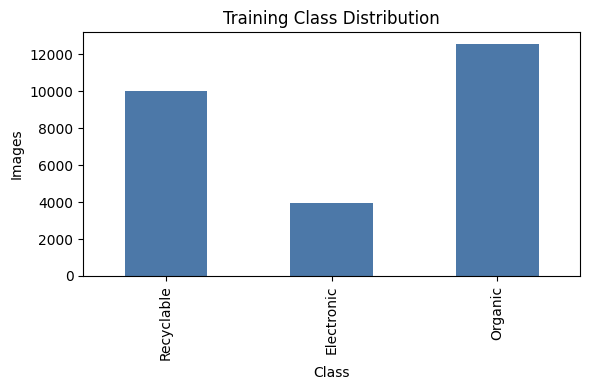

In [ ]:
def natural_key(value: str) -> list[Any]:
    """Sort strings with embedded numbers naturally."""
    return [int(part) if part.isdigit() else part.lower() for part in re.split(r"(\d+)", value)]


def count_image_files(directory: Path, recursive: bool = True) -> int:
    if not directory.exists():
        return 0
    iterator = directory.rglob("*") if recursive else directory.iterdir()
    return sum(1 for p in iterator if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)


def normalize_label(value: Any) -> int:
    if pd.isna(value):
        raise ValueError("Missing label")
    text = str(value).strip()
    if text.isdigit():
        label = int(text)
    else:
        key = text.lower().replace(" ", "_")
        letter_map = {"o": 0, "r": 1, "e": 2}
        if key in letter_map:
            label = letter_map[key]
        else:
            if key not in LABEL_NAME_TO_ID:
                raise ValueError(f"Unknown label: {value!r}")
            label = LABEL_NAME_TO_ID[key]
    if label not in CLASS_NAMES:
        raise ValueError(f"Unexpected label: {label}")
    return label


def load_metadata_from_folders(train_dir: Path) -> pd.DataFrame:
    rows: list[dict[str, Any]] = []
    for folder, label in CLASS_DIR_TO_LABEL.items():
        class_dir = train_dir / folder
        if not class_dir.exists():
            raise FileNotFoundError(f"Missing class folder: {class_dir}")
        files = sorted(
            [p for p in class_dir.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS],
            key=lambda p: natural_key(p.name),
        )
        for path in files:
            rows.append({
                "image_id": path.relative_to(train_dir).as_posix(),
                "image_path": str(path.resolve()),
                "label": label,
                "class_name": CLASS_NAMES[label],
            })
    return pd.DataFrame(rows)


def load_metadata_from_csv(train_csv: Path, train_dir: Path) -> pd.DataFrame:
    frame = pd.read_csv(train_csv)
    cols_lower = {c.lower(): c for c in frame.columns}
    image_col = cols_lower.get("image_path") or cols_lower.get("path") or cols_lower.get("filename") or cols_lower.get("file") or cols_lower.get("image")
    label_col = cols_lower.get("label") or cols_lower.get("class") or cols_lower.get("target")
    id_col = cols_lower.get("image_id") or cols_lower.get("id") or image_col
    if image_col is None or label_col is None:
        raise ValueError(f"Could not infer image/label columns from {frame.columns.tolist()}")
    rows: list[dict[str, Any]] = []
    for record in frame.to_dict("records"):
        image_path = Path(str(record[image_col]))
        if not image_path.is_absolute():
            image_path = train_dir / image_path
        label = normalize_label(record[label_col])
        rows.append({
            "image_id": str(record[id_col]),
            "image_path": str(image_path.resolve()),
            "label": label,
            "class_name": CLASS_NAMES[label],
        })
    return pd.DataFrame(rows)


def validate_train_metadata(df: pd.DataFrame) -> None:
    required = {"image_id", "image_path", "label", "class_name"}
    assert required.issubset(df.columns), f"Missing columns: {required - set(df.columns)}"
    assert df["label"].notna().all(), "Missing labels"
    assert set(df["label"].unique()).issubset({0, 1, 2}), "Labels must be only 0,1,2"
    assert not df["image_id"].duplicated().any(), "Duplicate image IDs"
    missing = [p for p in df["image_path"].map(Path) if not p.exists()]
    assert not missing, f"Missing image paths: {missing[:5]}"
    test_root = TEST_DIR.resolve() if TEST_DIR.exists() else None
    if test_root is not None:
        for p in df["image_path"].map(Path):
            rp = p.resolve()
            assert rp != test_root and test_root not in rp.parents, f"Test path leaked into train metadata: {p}"
    if EXPECTED_TRAIN_ROWS and len(df) != EXPECTED_TRAIN_ROWS:
        print(f"WARNING: expected {EXPECTED_TRAIN_ROWS} train rows, found {len(df)}")


print("Train dir:", TRAIN_DIR, TRAIN_DIR.exists())
print("Test dir:", TEST_DIR, TEST_DIR.exists())
print("Train image count:", count_image_files(TRAIN_DIR, recursive=True))
print("Test image count:", count_image_files(TEST_DIR, recursive=False))

if TRAIN_CSV and TRAIN_CSV.exists():
    train_df = load_metadata_from_csv(TRAIN_CSV, TRAIN_DIR)
else:
    train_df = load_metadata_from_folders(TRAIN_DIR)

train_df = train_df.sort_values("image_id", key=lambda s: s.map(natural_key)).reset_index(drop=True)
validate_train_metadata(train_df)

print("Train metadata:", train_df.shape)
display(train_df.head())
counts = train_df.groupby(["label", "class_name"]).size().rename("count").reset_index()
display(counts)

ax = counts.plot.bar(x="class_name", y="count", legend=False, figsize=(6, 4), color="#4c78a8")
ax.set_title("Training Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Images")
plt.tight_layout()
plt.show()


## 6. Pembagian Data Latih dan Validasi

`train_df` dibagi satu kali secara *stratified* berdasarkan kelas dengan `VAL_SPLIT_RATIO = 0.10` dan `SEED = 1000`. Hasilnya 23.874 citra untuk subset `train` dan 2.653 citra untuk subset `val`.

Baris hasil augmentasi mewarisi *split* dari citra aslinya. Dengan demikian, citra validasi tidak pernah muncul dalam pelatihan, termasuk dalam bentuk augmentasi. Pembagian ini menjadi satu-satunya dasar pemilihan *checkpoint*.

In [ ]:
from sklearn.model_selection import train_test_split

train_df = train_df.copy()

train_idx, val_idx = train_test_split(
    train_df.index.to_numpy(),
    test_size=VAL_SPLIT_RATIO,
    random_state=SEED,
    stratify=train_df["label"].to_numpy(),
)

train_df["split"] = "train"
train_df.loc[val_idx, "split"] = "val"
train_df["fold"] = (train_df["split"] == "val").astype(int)  # 0=train, 1=val (backward-compat)

assert set(train_df["split"].unique()) == {"train", "val"}
assert len(set(train_idx) & set(val_idx)) == 0, "train/val index overlap!"

split_counts = train_df.groupby(["split", "class_name"]).size().unstack(fill_value=0)
print(f"Stratified train/val split (val_ratio={VAL_SPLIT_RATIO}, seed={SEED}):")
display(split_counts)
print(f"Train rows: {(train_df['split'] == 'train').sum()} | "
      f"Val rows: {(train_df['split'] == 'val').sum()}")


Stratified train/val split (val_ratio=0.1, seed=1000):


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


class_name,Electronic,Organic,Recyclable
split,,,
train,3565,11310,8999
val,396,1257,1000


Train rows: 23874 | Val rows: 2653


## 7. Praproses Deterministik dan Pemuatan *Cache* Augmentasi

Citra asli, citra validasi, dan citra uji melalui praproses yang sama:

1. Koreksi orientasi EXIF.
2. Konversi ke RGB.
3. Penyesuaian ukuran dengan mempertahankan rasio aspek.
4. *Padding* menjadi kanvas persegi 224 × 224 piksel.
5. Normalisasi per kanal.

Augmentasi tidak dibuat di notebook ini. *View* augmentasi dibaca dari *cache* `aug-bdc-v1` yang dibuat pada notebook terpisah. Sel kedua pada bagian ini memeriksa kelengkapan *cache* terhadap `train_df`, yaitu apakah ada citra yang belum memiliki *view* augmentasi atau sebaliknya.

Preprocessing shape check passed


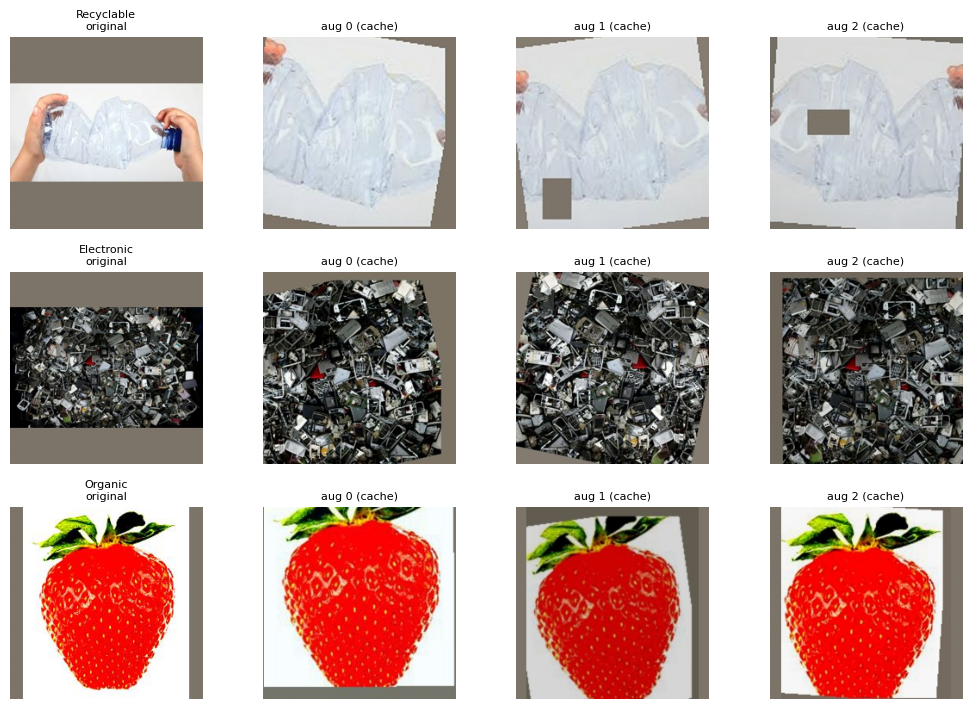

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
VISION_MEAN = [0.485, 0.456, 0.406]
VISION_STD = [0.229, 0.224, 0.225]


def default_padding_from_mean(mean: list[float]) -> tuple[int, int, int]:
    return tuple(int(round(float(m) * 255)) for m in mean)


def resize_and_pad(image: Image.Image, size: int, fill: tuple[int, int, int]) -> Image.Image:
    """Resize to fit inside a square, preserving aspect ratio, then pad."""
    image = image.convert("RGB")
    width, height = image.size
    if width <= 0 or height <= 0:
        raise ValueError(f"Invalid image size: {image.size}")
    scale = min(size / width, size / height)
    new_w = max(1, int(round(width * scale)))
    new_h = max(1, int(round(height * scale)))
    resized = image.resize((new_w, new_h), Image.Resampling.BICUBIC)
    canvas = Image.new("RGB", (size, size), fill)
    canvas.paste(resized, ((size - new_w) // 2, (size - new_h) // 2))
    assert canvas.size == (size, size)
    return canvas


def preprocess_original_image(
    image: Image.Image,
    *,
    size: int = IMAGE_SIZE,
    mean: Optional[list[float]] = None,
    std: Optional[list[float]] = None,
    padding_value: Optional[tuple[int, int, int]] = None,
) -> torch.Tensor:
    """Preprocess an image that is already in its final visual form.

    Used for BOTH original images and precomputed-augmented cache images -- the
    cache images were already augmented + resized/padded when the cache was built,
    so all that's left here is resize/pad (a safe no-op for cache images) + normalize.
    """
    mean = VISION_MEAN if mean is None else mean
    std = VISION_STD if std is None else std
    fill = default_padding_from_mean(mean) if padding_value is None else padding_value
    image = ImageOps.exif_transpose(image).convert("RGB")
    image = resize_and_pad(image, size=size, fill=fill)
    tensor = transforms.functional.to_tensor(image)
    tensor = transforms.functional.normalize(tensor, mean=mean, std=std)
    assert tensor.shape == (3, size, size)
    assert torch.isfinite(tensor).all()
    return tensor


def preprocess_tta_view(
    image: Image.Image,
    view_idx: int,
    *,
    size: int = IMAGE_SIZE,
    mean: Optional[list[float]] = None,
    std: Optional[list[float]] = None,
    padding_value: Optional[tuple[int, int, int]] = None,
) -> torch.Tensor:
    """Deterministic TTA view generator.

    view_idx 0 is the identity view -- pixel-identical to preprocess_original_image,
    so it doubles as a free "no-TTA" baseline when comparing against the TTA-averaged
    prediction (no extra forward pass needed).

    Views:
      0 = identity (no change)
      1 = horizontal flip
      2 = center crop to 90% (slight zoom-in)
      3 = rotate +7 degrees
      4 = rotate -7 degrees
    """
    mean = VISION_MEAN if mean is None else mean
    std = VISION_STD if std is None else std
    fill = default_padding_from_mean(mean) if padding_value is None else padding_value
    image = ImageOps.exif_transpose(image).convert("RGB")

    if view_idx == 0:
        pass
    elif view_idx == 1:
        image = ImageOps.mirror(image)
    elif view_idx == 2:
        width, height = image.size
        crop_w, crop_h = int(round(width * 0.9)), int(round(height * 0.9))
        left = (width - crop_w) // 2
        top = (height - crop_h) // 2
        image = image.crop((left, top, left + crop_w, top + crop_h))
    elif view_idx == 3:
        image = image.rotate(7, resample=Image.Resampling.BICUBIC, expand=True, fillcolor=fill)
    elif view_idx == 4:
        image = image.rotate(-7, resample=Image.Resampling.BICUBIC, expand=True, fillcolor=fill)
    else:
        raise ValueError(f"Unsupported TTA view_idx={view_idx} (only 0-4 defined, TTA_N_VIEWS=5)")

    image = resize_and_pad(image, size=size, fill=fill)
    tensor = transforms.functional.to_tensor(image)
    tensor = transforms.functional.normalize(tensor, mean=mean, std=std)
    assert tensor.shape == (3, size, size)
    assert torch.isfinite(tensor).all()
    return tensor


def load_augmented_manifest(expected_images: Optional[int] = None) -> pd.DataFrame:
    """Load the precomputed augmented-image manifest from the external cache dataset.

    The cache (augmented JPEGs + manifest.csv) was generated once in a separate
    notebook (build_aug_cache) and uploaded as its own Kaggle dataset. This notebook
    only reads it -- no augmentation is generated here.
    """
    manifest_path = AUG_IMAGE_CACHE_DIR / "manifest.csv"
    if not manifest_path.exists():
        raise RuntimeError(
            f"manifest.csv not found at {manifest_path}. "
            "Check that the aug-bdc-v1 dataset is attached and AUG_IMAGE_CACHE_DIR is correct."
        )
    manifest = pd.read_csv(manifest_path)
    expected_rows = None if expected_images is None else expected_images * AUGS_PER_IMAGE
    if expected_rows is not None and len(manifest) != expected_rows:
        raise RuntimeError(
            f"Cache manifest has {len(manifest)} rows, expected {expected_rows}. "
            "Check AUGS_PER_IMAGE or the dataset attached."
        )

    # manifest['cache_path'] is relative to the build notebook's OUTPUT_DIR and already
    # starts with 'aug_image_cache/<hash>/...', which lines up with the dataset's own
    # folder layout once we join it back onto AUG_IMAGE_CACHE_ROOT's parent.
    manifest = manifest.copy()
    manifest["image_path"] = manifest["cache_path"].apply(
        lambda p: str((AUG_IMAGE_CACHE_ROOT.parent / p).resolve())
    )

    # Inherit each cached row's train/val split from its base image so validation
    # images are never trained on, even in augmented form.
    split_map = train_df.set_index("image_id")["split"]
    manifest["split"] = manifest["image_id"].map(split_map)
    if manifest["split"].isna().any():
        missing = manifest.loc[manifest["split"].isna(), "image_id"].unique()
        raise RuntimeError(
            f"{len(missing)} cached image_id(s) have no train/val split assignment "
            f"(train_df split cell must run before this), e.g. {list(missing[:5])}"
        )
    manifest["fold"] = (manifest["split"] == "val").astype(int)  # 0=train, 1=val (backward-compat)
    return manifest


def tensor_to_display_image(tensor: torch.Tensor, mean: list[float], std: list[float]) -> np.ndarray:
    t = tensor.detach().cpu().clone()
    t = t * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)
    return t.clamp(0, 1).permute(1, 2, 0).numpy()


PADDING_VALUE = PADDING_VALUE or default_padding_from_mean(VISION_MEAN)
example = train_df.iloc[0]
with Image.open(example.image_path) as im:
    original_tensor = preprocess_original_image(im, padding_value=PADDING_VALUE)
assert original_tensor.shape == (3, IMAGE_SIZE, IMAGE_SIZE)
print("Preprocessing shape check passed")

if SHOW_PREPROCESSING_SAMPLES or SHOW_AUGMENTATION_SAMPLES:
    preview_manifest = load_augmented_manifest(expected_images=len(train_df))
    rows = train_df.groupby("label", group_keys=False).head(1).reset_index(drop=True)
    n_aug_preview = min(AUGS_PER_IMAGE, 3)
    fig, axes = plt.subplots(len(rows), 1 + n_aug_preview, figsize=(2.6 * (1 + n_aug_preview), 2.4 * len(rows)))
    axes = np.asarray(axes).reshape(len(rows), -1)
    for r, row in enumerate(rows.itertuples(index=False)):
        with Image.open(row.image_path) as im:
            tensor = preprocess_original_image(im, padding_value=PADDING_VALUE)
        axes[r, 0].imshow(tensor_to_display_image(tensor, VISION_MEAN, VISION_STD))
        axes[r, 0].set_title(f"{row.class_name}\noriginal", fontsize=8)
        axes[r, 0].axis("off")
        aug_rows = preview_manifest[preview_manifest["image_id"] == row.image_id].sort_values("aug_idx")
        for a in range(n_aug_preview):
            if a >= len(aug_rows):
                axes[r, a + 1].axis("off")
                continue
            aug_row = aug_rows.iloc[a]
            with Image.open(aug_row.image_path) as im:
                tensor = preprocess_original_image(im, padding_value=PADDING_VALUE)
            axes[r, a + 1].imshow(tensor_to_display_image(tensor, VISION_MEAN, VISION_STD))
            axes[r, a + 1].set_title(f"aug {a} (cache)", fontsize=8)
            axes[r, a + 1].axis("off")
    plt.tight_layout()
    plt.show()


In [ ]:
# Sanity check: which train_df images are missing an augmented cache entry (or vice versa).
manifest_raw = pd.read_csv(AUG_IMAGE_CACHE_DIR / "manifest.csv")

cached_ids = set(manifest_raw["image_id"].unique())
current_ids = set(train_df["image_id"].unique())

missing_from_cache = current_ids - cached_ids   # in train_df now, but not in the cache
extra_in_cache = cached_ids - current_ids        # in the cache, but no longer used

print(f"train_df now      : {len(current_ids)} images")
print(f"manifest cache     : {len(cached_ids)} images")
print(f"missing_from_cache : {len(missing_from_cache)} images (no augmented view)")
print(f"extra_in_cache     : {len(extra_in_cache)} images (in cache but unused)")

if missing_from_cache:
    missing_df = train_df[train_df["image_id"].isin(missing_from_cache)]
    print("\nMissing per class:")
    print(missing_df["class_name"].value_counts())

print("\nExample missing ids:", list(missing_from_cache)[:10])


train_df now      : 26527 images
manifest cache     : 26527 images
missing_from_cache : 0 images (no augmented view)
extra_in_cache     : 0 images (in cache but unused)

Example missing ids: []


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 8. *Encoder* SigLIP 2 dengan *Partial Fine-Tuning*

Langkah pada sel berikut:

1. Memuat menara visual SigLIP 2 SO400M. Menara teks dan proyeksi multimodal dibuang karena hanya menara visual yang dibutuhkan.
2. Membekukan seluruh parameter.
3. Membuka kembali satu lapisan *transformer* terakhir, *post-layernorm*, dan *pooler head*. *Patch embedding* tetap beku.
4. Membentuk representasi fitur berdimensi 2.304 dengan menggabungkan *pooled output* (1.152) dan hasil *attention pooling* atas token *patch* (1.152).
5. Membungkus *feature extractor* dengan `nn.DataParallel` agar dua GPU dapat bekerja bersamaan.

In [ ]:
import os
os.environ.setdefault("HF_HOME", "/kaggle/working/hf_cache")  # cache biar gak fetch ulang tiap cell re-run

print("SigLIP2 checkpoint yang dipakai:", MODEL_NAME)


@dataclass
class EncoderInfo:
    model_name: str
    hidden_size: int
    num_hidden_layers: Optional[int]
    patch_size: Optional[int]
    num_register_tokens: int
    parameter_count: int
    trainable_parameter_count: int
    image_mean: list[float]
    image_std: list[float]


def get_config_value(config: Any, names: list[str], default: Any = None) -> Any:
    for name in names:
        if hasattr(config, name):
            return getattr(config, name)
        if isinstance(config, dict) and name in config:
            return config[name]
    return default


def vision_config_from_model(model: nn.Module) -> Any:
    """Return the vision config for SigLIP model variants."""
    config = getattr(model, "config", None)
    vision_config = getattr(config, "vision_config", None)
    return vision_config if vision_config is not None else config


def require_siglip_name(model_name: str) -> None:
    """Allow public SigLIP repo IDs or local folders with SigLIP config files."""
    name = str(model_name)
    lowered = name.lower()
    path = Path(name)
    if path.exists():
        config_path = path / "config.json"
        if not config_path.exists():
            raise ValueError(f"Local MODEL_NAME exists but lacks config.json: {model_name!r}")
        try:
            config_data = json.loads(config_path.read_text(encoding="utf-8"))
        except Exception as exc:
            raise ValueError(f"Could not read local model config: {config_path}") from exc
        model_type = str(config_data.get("model_type", "")).lower()
        vision_type = str(config_data.get("vision_config", {}).get("model_type", "")).lower()
        if "siglip" not in model_type and "siglip" not in vision_type:
            raise ValueError(f"Local MODEL_NAME is not a SigLIP model: {model_name!r}")
        return
    # Not a local path -> assume an HF hub repo id. Just make sure it's SigLIP.
    if "siglip" not in lowered:
        raise ValueError(f"MODEL_NAME must be a SigLIP checkpoint or local model folder, got {model_name!r}")


def unfreeze_layers(
    encoder_model: nn.Module,
    num_unfreeze: int,
    unfreeze_post_ln: bool,
    unfreeze_pooler: bool,
) -> int:
    """Freeze all, then selectively unfreeze last N transformer layers + optional components.

    IMPORTANT: The patch embedding layer (vision.embeddings) is ALWAYS kept frozen.
    """
    for param in encoder_model.parameters():
        param.requires_grad = False

    vision = encoder_model.vision_model
    if hasattr(vision, "embeddings"):
        for param in vision.embeddings.parameters():
            param.requires_grad = False

    total_layers = len(vision.encoder.layers)
    if num_unfreeze >= total_layers:
        raise ValueError(
            f"num_unfreeze={num_unfreeze} would unfreeze all {total_layers} transformer layers "
            f"and reach the embedding layer. Keep num_unfreeze < total_layers."
        )
    freeze_up_to = total_layers - num_unfreeze

    for i in range(freeze_up_to, total_layers):
        vision.encoder.layers[i].requires_grad_(True)

    if unfreeze_post_ln:
        vision.post_layernorm.requires_grad_(True)

    if unfreeze_pooler and getattr(vision, "head", None) is not None:
        vision.head.requires_grad_(True)

    return sum(p.numel() for p in encoder_model.parameters() if p.requires_grad)


def load_siglip_encoder(
    model_name: str,
    num_unfreeze: int,
    unfreeze_post_ln: bool,
    unfreeze_pooler: bool,
    dtype: torch.dtype = torch.float32,
    gradient_checkpointing: bool = False,
) -> tuple[nn.Module, Any, EncoderInfo]:
    """Load a SigLIP model directly from HF Hub, freeze/unfreeze layers, return encoder + info."""
    require_siglip_name(model_name)
    if not TRANSFORMERS_AVAILABLE:
        raise RuntimeError(f"transformers is unavailable: {TRANSFORMERS_IMPORT_ERROR}")
    assert AutoImageProcessor is not None and AutoModel is not None

    print(f"Downloading/loading {model_name} from HF hub (needs Internet: ON on Kaggle)...")
    try:
        processor = AutoImageProcessor.from_pretrained(model_name, trust_remote_code=TRUST_REMOTE_CODE)
        encoder_model = AutoModel.from_pretrained(
            model_name,
            trust_remote_code=TRUST_REMOTE_CODE,
            torch_dtype=dtype,
        )
    except Exception as exc:
        raise RuntimeError(
            f"Could not load {model_name} from HF hub. Check the Internet toggle in Kaggle "
            f"Settings and that the repo id is correct. Original error: {exc}"
        ) from exc

    print(f"Loaded {model_name} successfully from HF hub.")

    if gradient_checkpointing and hasattr(encoder_model.vision_model.encoder, "gradient_checkpointing_enable"):
        encoder_model.vision_model.encoder.gradient_checkpointing_enable()

    # Drop the text encoder (and any multimodal projection) -- we only need vision.
    if hasattr(encoder_model, "text_model"):
        del encoder_model.text_model
    if hasattr(encoder_model, "text_projection"):
        del encoder_model.text_projection
    if hasattr(encoder_model, "vision_projection"):
        del encoder_model.vision_projection
    if hasattr(encoder_model, "logit_scale"):
        del encoder_model.logit_scale
    if hasattr(encoder_model, "logit_bias"):
        del encoder_model.logit_bias
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    encoder_model.eval()
    trainable_count = unfreeze_layers(encoder_model, num_unfreeze, unfreeze_post_ln, unfreeze_pooler)

    vcfg = vision_config_from_model(encoder_model)
    hidden_size = int(get_config_value(vcfg, ["hidden_size", "embed_dim"], None))
    num_layers = get_config_value(vcfg, ["num_hidden_layers", "depth", "num_layers"], None)
    patch_size = get_config_value(vcfg, ["patch_size"], None)
    patch_size = int(patch_size) if patch_size is not None else None
    num_register_tokens = 0
    image_mean = [float(x) for x in getattr(processor, "image_mean", VISION_MEAN)]
    image_std = [float(x) for x in getattr(processor, "image_std", VISION_STD)]

    info = EncoderInfo(
        model_name=model_name,
        hidden_size=hidden_size,
        num_hidden_layers=int(num_layers) if num_layers is not None else None,
        patch_size=patch_size,
        num_register_tokens=num_register_tokens,
        parameter_count=sum(p.numel() for p in encoder_model.parameters()),
        trainable_parameter_count=trainable_count,
        image_mean=image_mean,
        image_std=image_std,
    )
    return encoder_model, processor, info


def get_siglip_vision_outputs(encoder_model: nn.Module, pixel_values: torch.Tensor) -> Any:
    if hasattr(encoder_model, "vision_model"):
        return encoder_model.vision_model(pixel_values=pixel_values, output_hidden_states=False, return_dict=True)
    outputs = encoder_model(pixel_values=pixel_values, output_hidden_states=False, return_dict=True)
    if hasattr(outputs, "vision_model_output") and outputs.vision_model_output is not None:
        return outputs.vision_model_output
    return outputs


def get_last_hidden_state(outputs: Any) -> torch.Tensor:
    if hasattr(outputs, "last_hidden_state") and outputs.last_hidden_state is not None:
        return outputs.last_hidden_state
    if isinstance(outputs, dict) and "last_hidden_state" in outputs:
        return outputs["last_hidden_state"]
    if isinstance(outputs, (tuple, list)) and outputs:
        return outputs[0]
    raise TypeError("Could not find token-level hidden state in SigLIP vision outputs")


def get_pooler_output(outputs: Any, tokens: torch.Tensor) -> torch.Tensor:
    if hasattr(outputs, "pooler_output") and outputs.pooler_output is not None:
        pooled = outputs.pooler_output
    elif isinstance(outputs, dict) and outputs.get("pooler_output") is not None:
        pooled = outputs["pooler_output"]
    else:
        pooled = tokens.mean(dim=1)
    assert pooled.ndim == 2, pooled.shape
    return pooled


class AttentionPool(nn.Module):
    """Small learnable attention-pooling layer over patch tokens.

    A single learnable query vector attends over all patch tokens and returns a
    weighted sum -- this lets the model "pick" the most discriminative regions
    instead of averaging every patch equally. Replaces plain mean-pooling as the
    second half of the combined feature vector (pooled_output stays the same,
    from SigLIP's own pretrained pooler head).
    """

    def __init__(self, hidden_size: int) -> None:
        super().__init__()
        self.hidden_size = int(hidden_size)
        self.query = nn.Parameter(torch.zeros(1, 1, self.hidden_size))
        nn.init.trunc_normal_(self.query, std=0.02)
        self.k_proj = nn.Linear(self.hidden_size, self.hidden_size)
        self.v_proj = nn.Linear(self.hidden_size, self.hidden_size)
        self.out_proj = nn.Linear(self.hidden_size, self.hidden_size)
        self.scale = self.hidden_size ** -0.5

    def forward(self, patch_tokens: torch.Tensor) -> torch.Tensor:
        # patch_tokens: (B, N, D)
        assert patch_tokens.ndim == 3 and patch_tokens.shape[-1] == self.hidden_size, patch_tokens.shape
        batch = patch_tokens.shape[0]
        query = self.query.expand(batch, -1, -1).to(patch_tokens.dtype)   # (B, 1, D)
        keys = self.k_proj(patch_tokens)                                  # (B, N, D)
        values = self.v_proj(patch_tokens)                                # (B, N, D)
        attn_logits = torch.matmul(query, keys.transpose(-2, -1)) * self.scale  # (B, 1, N)
        attn_weights = attn_logits.softmax(dim=-1)
        pooled = torch.matmul(attn_weights, values)                       # (B, 1, D)
        pooled = self.out_proj(pooled.squeeze(1))                         # (B, D)
        assert pooled.shape == (batch, self.hidden_size), pooled.shape
        assert torch.isfinite(pooled).all()
        return pooled


def extract_combined_features(
    encoder_model: nn.Module,
    pixel_values: torch.Tensor,
    hidden_size: int,
    num_register_tokens: int,
    attn_pool: nn.Module,
) -> torch.Tensor:
    del num_register_tokens
    outputs = get_siglip_vision_outputs(encoder_model, pixel_values)
    tokens = get_last_hidden_state(outputs)
    assert tokens.ndim == 3, tokens.shape
    batch, token_count, width = tokens.shape
    assert token_count > 0, "No visual tokens returned"
    assert width == hidden_size, f"Hidden width mismatch: {width} != {hidden_size}"
    pooled_feature = get_pooler_output(outputs, tokens)
    assert pooled_feature.shape == (batch, hidden_size), pooled_feature.shape
    attn_patch = attn_pool(tokens)
    assert attn_patch.shape == (batch, hidden_size), attn_patch.shape
    combined = torch.cat([pooled_feature, attn_patch], dim=1)
    assert combined.shape == (batch, 2 * hidden_size)
    assert torch.isfinite(combined).all()
    return combined


def count_trainable_params(model: nn.Module) -> dict[str, int]:
    counts: dict[str, int] = {}
    total = 0
    for name, param in model.named_parameters():
        if param.requires_grad:
            total += param.numel()
            prefix = name.split(".")[0]
            counts[prefix] = counts.get(prefix, 0) + param.numel()
    return {"total_trainable": total, "by_prefix": counts}


NEEDS_ENCODER = RUN_ENCODER_SMOKE_TEST or RUN_FINETUNE_TRAINING or RUN_TEST_INFERENCE
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
encoder: Optional[nn.Module] = None
encoder_info: Optional[EncoderInfo] = None
image_processor: Any = None
attn_pool: Optional[nn.Module] = None  # learnable attention-pooling over patch tokens

if NEEDS_ENCODER:
    encoder, image_processor, encoder_info = load_siglip_encoder(
        MODEL_NAME,
        num_unfreeze=UNFREEZE_LAYERS,
        unfreeze_post_ln=UNFREEZE_POST_LN,
        unfreeze_pooler=UNFREEZE_POOLER,
        dtype=MODEL_LOAD_DTYPE,
        gradient_checkpointing=USE_GRADIENT_CHECKPOINTING,
    )
    encoder = encoder.to(DEVICE)
    VISION_MEAN = encoder_info.image_mean
    VISION_STD = encoder_info.image_std
    PADDING_VALUE = default_padding_from_mean(VISION_MEAN) if PADDING_VALUE is None else PADDING_VALUE
    print(json.dumps(asdict(encoder_info), indent=2))
    print(f"Trainable params: {encoder_info.trainable_parameter_count:,} / {encoder_info.parameter_count:,} total")

    trainable_breakdown = count_trainable_params(encoder)
    print("\nTrainable parameter breakdown:")
    for prefix, count in sorted(trainable_breakdown["by_prefix"].items(), key=lambda x: -x[1]):
        print(f"  {prefix}: {count:,}")

    # Learnable attention-pooling over patch tokens, replaces mean-pooling.
    # Always trainable (fresh random init), same spirit as the classifier head.
    attn_pool = AttentionPool(encoder_info.hidden_size).to(DEVICE)
    attn_pool_param_count = sum(p.numel() for p in attn_pool.parameters())
    print(f"AttentionPool (replaces mean-pool): {attn_pool_param_count:,} trainable params")
else:
    print("Skipping SigLIP load because encoder-dependent flags are disabled.")

if RUN_ENCODER_SMOKE_TEST:
    assert encoder is not None and encoder_info is not None
    smoke = train_df.head(2)
    tensors = []
    for row in smoke.itertuples(index=False):
        with Image.open(row.image_path) as im:
            tensors.append(preprocess_original_image(im, mean=VISION_MEAN, std=VISION_STD, padding_value=PADDING_VALUE))
    batch = torch.stack(tensors).to(DEVICE)

    encoder.train()
    batch.requires_grad_(True)
    use_amp_smoke = USE_AMP_FOR_FINETUNE and DEVICE.type == "cuda"
    with torch.autocast(device_type="cuda", dtype=MODEL_DTYPE, enabled=use_amp_smoke):
        outputs = encoder.vision_model(pixel_values=batch, output_hidden_states=False, return_dict=True)
        tokens = outputs.last_hidden_state
        pooled = outputs.pooler_output
        assert tokens.shape == (2, tokens.shape[1], encoder_info.hidden_size)
        assert pooled.shape == (2, encoder_info.hidden_size)
        combined = extract_combined_features(
            encoder, batch, encoder_info.hidden_size, encoder_info.num_register_tokens, attn_pool
        )
    assert combined.shape == (2, 2 * encoder_info.hidden_size)
    loss = combined.sum()
    loss.backward()
    grad_flows = False
    for name, param in encoder.named_parameters():
        if param.requires_grad and param.grad is not None:
            grad_flows = True
            break
    assert grad_flows, "No gradients flowing through unfrozen parameters!"
    attn_pool_grad_flows = any(p.grad is not None for p in attn_pool.parameters())
    assert attn_pool_grad_flows, "No gradients flowing through AttentionPool!"
    print("Encoder smoke test passed:", tuple(combined.shape))
    print("Gradient flow verified: unfrozen parameters + AttentionPool receive gradients")
    encoder.zero_grad(set_to_none=True)
    attn_pool.zero_grad(set_to_none=True)
    encoder.eval()
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ---- Dual-GPU feature extractor wrapper ----
class SiglipFeatureExtractor(nn.Module):
    def __init__(self, encoder_model: nn.Module, hidden_size: int, num_register_tokens: int,
                 attn_pool: nn.Module) -> None:
        super().__init__()
        self.encoder_model = encoder_model
        self.hidden_size = int(hidden_size)
        self.num_register_tokens = int(num_register_tokens)
        self.attn_pool = attn_pool  # learnable attention-pooling over patch tokens

    def forward(self, pixel_values: torch.Tensor) -> torch.Tensor:
        use_amp = USE_AMP_FOR_FINETUNE and pixel_values.is_cuda
        with torch.autocast(device_type="cuda", dtype=MODEL_DTYPE, enabled=use_amp):
            return extract_combined_features(
                self.encoder_model, pixel_values, self.hidden_size, self.num_register_tokens, self.attn_pool
            )


def unwrap_encoder(fe: nn.Module) -> nn.Module:
    base = fe.module if isinstance(fe, nn.DataParallel) else fe
    return base.encoder_model


def unwrap_feature_extractor(fe: nn.Module) -> nn.Module:
    """Return the SiglipFeatureExtractor wrapper itself (unwrapped from DataParallel) --
    use this (not unwrap_encoder) to reach `.attn_pool`."""
    return fe.module if isinstance(fe, nn.DataParallel) else fe


feature_extractor: Optional[nn.Module] = None
N_GPUS = torch.cuda.device_count()
USE_DATA_PARALLEL = bool(USE_MULTI_GPU and N_GPUS > 1)
if NEEDS_ENCODER and encoder is not None and encoder_info is not None:
    feature_extractor = SiglipFeatureExtractor(
        encoder, encoder_info.hidden_size, encoder_info.num_register_tokens, attn_pool
    )
    if USE_DATA_PARALLEL:
        feature_extractor = nn.DataParallel(feature_extractor)
        print(f"nn.DataParallel enabled across {N_GPUS} GPUs "
              f"(effective batch {BATCH_SIZE_FINETUNE}).")
    else:
        print(f"Single-device feature extractor (GPUs visible: {N_GPUS}).")


SigLIP2 checkpoint yang dipakai: google/siglip2-so400m-patch14-224
Downloading/loading google/siglip2-so400m-patch14-224 from HF hub (needs Internet: ON on Kaggle)...


preprocessor_config.json:   0%|          | 0.00/394 [00:00<?, ?B/s]

The image processor of type `SiglipImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json:   0%|          | 0.00/536 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyPacked has no __module__ attribute
<frozen importlib._bootstrap>:488: DeprecationWarning: builtin type SwigPyObject has no __module__ attribute


model.safetensors:   0%|          | 0.00/4.54G [00:00<?, ?B/s]

sys:1: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x79538c802040>
sys:1: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x79538c802200>
sys:1: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x79538c802120>
sys:1: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x79538c802ba0>
sys:1: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x79538c802c80>
sys:1: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x79538c802eb0>
sys:1: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x79538c802f90>
sys:1: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x79538c803070>
sys:1: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x79538c803150>
sys:1: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x79538c8030e0>
sys:1: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x79538c8031c0>
sys:1: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x79538c8033f0>
sys:1: ResourceWarning: Uncl

Loading weights:   0%|          | 0/888 [00:00<?, ?it/s]

Loaded google/siglip2-so400m-patch14-224 successfully from HF hub.
{
  "model_name": "google/siglip2-so400m-patch14-224",
  "hidden_size": 1152,
  "num_hidden_layers": 27,
  "patch_size": 14,
  "num_register_tokens": 0,
  "parameter_count": 427680704,
  "trainable_parameter_count": 30480160,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_std": [
    0.5,
    0.5,
    0.5
  ]
}
Trainable params: 30,480,160 / 427,680,704 total

Trainable parameter breakdown:
  vision_model: 30,480,160
AttentionPool (replaces mean-pool): 3,985,920 trainable params
Encoder smoke test passed: (2, 2304)
Gradient flow verified: unfrozen parameters + AttentionPool receive gradients
nn.DataParallel enabled across 2 GPUs (effective batch 256).


## 8a. Memuat *Cache* Augmentasi

Sel berikut membaca `manifest.csv` dari dataset *cache* `aug-bdc-v1` dan mencetak jumlah baris augmentasi. Jumlah baris harus sama dengan jumlah citra latih dikali `AUGS_PER_IMAGE`.

In [ ]:
manifest = load_augmented_manifest(expected_images=len(train_df))
print(f"Loaded augmented cache: {len(manifest)} rows from {AUG_IMAGE_CACHE_DIR}")


Loaded augmented cache: 106108 rows from /kaggle/input/datasets/user235162736/aug-bdc-v1/aug_image_cache/8315c7d99fb13736


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 9. *Dataset* Pelatihan dan Validasi

Kelas `FeatureImageDataset` memuat citra asli atau citra augmentasi. Karena `USE_AUGMENTED_IMAGE_CACHE = True`, baris augmentasi dibaca langsung dari *cache* dan tidak ada augmentasi yang dilakukan saat pelatihan. Sel ini juga mendefinisikan pengaturan `DataLoader`.

In [ ]:
def image_loader_worker_kwargs(num_workers: int) -> dict[str, Any]:
    """Return notebook-safe image DataLoader worker kwargs."""
    kwargs: dict[str, Any] = {"num_workers": int(num_workers), "pin_memory": torch.cuda.is_available()}
    if int(num_workers) > 0:
        if os.name == "posix" and USE_FORK_DATALOADER_WORKERS:
            kwargs["multiprocessing_context"] = "fork"
        kwargs["persistent_workers"] = True
    return kwargs


def build_original_feature_frame(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy().reset_index(drop=True)
    out["base_index"] = np.arange(len(out))
    out["aug_idx"] = -1
    out["cache_path"] = ""
    out["feature_id"] = out["image_id"].astype(str) + "::orig"
    return out


def build_augmented_feature_frame(df: pd.DataFrame, views_per_image: int) -> pd.DataFrame:
    """Augmented rows always come from the precomputed cache; nothing generated on-the-fly."""
    manifest = load_augmented_manifest(expected_images=len(df))
    return manifest.copy().reset_index(drop=True)


class FeatureImageDataset(Dataset):
    """Load images (original or precomputed-augmented) and preprocess them.

    Both original and cached-augmented images are already in their final visual
    form, so every row just goes through resize/pad + normalize here -- no
    augmentation is applied in this notebook.
    """

    def __init__(self, frame: pd.DataFrame, mean: list[float], std: list[float], padding_value: tuple[int, int, int],
                 view_idx: Optional[int] = None) -> None:
        self.frame = frame.reset_index(drop=True).copy()
        self.mean = mean
        self.std = std
        self.padding_value = padding_value
        # When set, every image is preprocessed with this deterministic TTA view
        # instead of the plain original preprocessing. None = unchanged behavior.
        self.view_idx = view_idx

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> dict[str, Any]:
        row = self.frame.iloc[index]
        path = Path(str(row.image_path))
        try:
            with Image.open(path) as image:
                if self.view_idx is None:
                    tensor = preprocess_original_image(
                        image,
                        size=IMAGE_SIZE,
                        mean=self.mean,
                        std=self.std,
                        padding_value=self.padding_value,
                    )
                else:
                    tensor = preprocess_tta_view(
                        image,
                        self.view_idx,
                        size=IMAGE_SIZE,
                        mean=self.mean,
                        std=self.std,
                        padding_value=self.padding_value,
                    )
        except Exception as exc:
            raise RuntimeError(f"Failed image preprocessing for {path}: {exc}") from exc
        return {
            "row_index": index,
            "feature_id": str(row.feature_id),
            "image_id": str(row.image_id),
            "image_path": str(path),
            "cache_path": str(row.cache_path) if "cache_path" in self.frame.columns else "",
            "base_index": int(row.base_index),
            "aug_idx": int(row.aug_idx),
            "label": int(row.label),
            "fold": int(row.fold),
            "pixel_values": tensor,
        }


def collate_feature_batch(items: list[dict[str, Any]]) -> dict[str, Any]:
    return {
        "row_index": torch.tensor([x["row_index"] for x in items], dtype=torch.long),
        "feature_id": [x["feature_id"] for x in items],
        "image_id": [x["image_id"] for x in items],
        "image_path": [x["image_path"] for x in items],
        "cache_path": [x["cache_path"] for x in items],
        "base_index": torch.tensor([x["base_index"] for x in items], dtype=torch.long),
        "aug_idx": torch.tensor([x["aug_idx"] for x in items], dtype=torch.long),
        "label": torch.tensor([x["label"] for x in items], dtype=torch.long),
        "fold": torch.tensor([x["fold"] for x in items], dtype=torch.long),
        "pixel_values": torch.stack([x["pixel_values"] for x in items]),
    }


## 10. Tabel Citra Asli dan Citra Augmentasi

Bagian ini membangun dua tabel yang menunjukkan citra mana yang akan dimuat:

1. Tabel citra asli, dengan kolom jalur yang menunjuk ke berkas citra latih.
2. Tabel citra augmentasi, dengan kolom jalur yang menunjuk ke berkas di *cache*.

Kedua tabel membawa kolom `split` dari bagian 6, sehingga pemisahan `train` dan `val` tetap konsisten.

In [ ]:
original_feature_frame = build_original_feature_frame(train_df)
augmented_feature_frame = build_augmented_feature_frame(train_df, AUGS_PER_IMAGE)
print("Original image rows:", len(original_feature_frame))
print("Augmented image rows:", len(augmented_feature_frame))
print("  original  train/val:", original_feature_frame["split"].value_counts().to_dict())
print("  augmented train/val:", augmented_feature_frame["split"].value_counts().to_dict())


Original image rows: 26527
Augmented image rows: 106108
  original  train/val: {'train': 23874, 'val': 2653}
  augmented train/val: {'train': 95496, 'val': 10612}


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 11. *Classifier Head* Hierarkis dan *Focal Loss*

Kelas *Electronic* relatif mudah dipisahkan dari kelas lain, sedangkan *Recyclable* dan *Organic* sering tertukar. Karena itu klasifikasi tidak memakai satu *head* tiga kelas, melainkan dua *head* biner yang menggunakan fitur 2.304 dimensi yang sama:

- Tahap 1 (`electronic_head`): *Electronic* melawan bukan *Electronic*.
- Tahap 2 (`recyclable_organic_head`): *Recyclable* melawan *Organic*, dilatih hanya pada citra non-*Electronic*.

Setiap *head* tersusun atas *LayerNorm*, *Linear* (512 unit), GELU, *Dropout* 0,3, dan *Linear* dengan keluaran dua unit. Kedua tahap digabung menjadi probabilitas tiga kelas melalui fungsi `hierarchical_probs`. *Loss* yang dipakai adalah *focal loss* (`FOCAL_GAMMA = 4`) pada tiap tahap, lalu dijumlahkan. Sel ini juga menjalankan pemeriksaan bahwa *head* dan *loss* bekerja sesuai rancangan.

In [ ]:
class HierarchicalClassifierHead(nn.Module):
    """Two-stage classifier head: LayerNorm -> Linear -> GELU -> Dropout -> Linear,
    once per stage.

    Stage 1 (electronic_head): Electronic vs Rest -- index 0 = not-electronic,
    index 1 = electronic.
    Stage 2 (recyclable_organic_head): Recyclable vs Organic -- index 0 =
    recyclable, index 1 = organic. Trained only on non-electronic rows, but runs
    on every row; only meaningful once combined with stage 1 via hierarchical_probs.
    """

    def __init__(self, feature_dim: int, hidden_dim: Optional[int] = None,
                 dropout: Optional[float] = None) -> None:
        super().__init__()
        hidden_dim = HEAD_HIDDEN_DIM if hidden_dim is None else hidden_dim
        dropout = HEAD_DROPOUT if dropout is None else dropout

        def _make_binary_head() -> nn.Sequential:
            return nn.Sequential(
                nn.LayerNorm(feature_dim),
                nn.Linear(feature_dim, hidden_dim),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(hidden_dim, 2),
            )

        self.electronic_head = _make_binary_head()
        self.recyclable_organic_head = _make_binary_head()

    def forward(self, features: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        return self.electronic_head(features), self.recyclable_organic_head(features)


def hierarchical_probs(electronic_logits: torch.Tensor, ro_logits: torch.Tensor) -> torch.Tensor:
    """Combine the two binary heads into 3-class probs matching CLASS_NAMES
    (0=Recyclable, 1=Electronic, 2=Organic)."""
    p_electronic = F.softmax(electronic_logits, dim=1)
    p_ro = F.softmax(ro_logits, dim=1)
    p_not_electronic = p_electronic[:, 0]
    p_e = p_electronic[:, 1]
    p_recyclable = p_not_electronic * p_ro[:, 0]
    p_organic = p_not_electronic * p_ro[:, 1]
    return torch.stack([p_recyclable, p_e, p_organic], dim=1)


class FocalLoss(nn.Module):
    """Binary/multiclass focal loss with optional per-class alpha weights."""

    def __init__(self, alpha: Optional[torch.Tensor] = None, gamma: float = 2.0,
                 reduction: str = "mean") -> None:
        super().__init__()
        self.gamma = float(gamma)
        self.reduction = reduction
        self.alpha = alpha  # 1D tensor of per-class weights, or None

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        log_probs = F.log_softmax(logits, dim=1)
        weight = self.alpha.to(logits.device, dtype=logits.dtype) if self.alpha is not None else None
        ce = F.nll_loss(log_probs, target, weight=weight, reduction="none")
        pt = log_probs.gather(1, target.unsqueeze(1)).squeeze(1).exp()
        loss = ((1.0 - pt) ** self.gamma) * ce
        if self.reduction == "mean":
            return loss.mean()
        if self.reduction == "sum":
            return loss.sum()
        return loss


def make_binary_class_weights(labels_tensor: torch.Tensor) -> Optional[torch.Tensor]:
    if not USE_CLASS_WEIGHTS:
        return None
    if CLASS_WEIGHT_MODE == "manual":
        if MANUAL_CLASS_WEIGHTS is None or len(MANUAL_CLASS_WEIGHTS) < 2:
            raise ValueError("MANUAL_CLASS_WEIGHTS must contain at least two values for binary heads")
        return torch.tensor(MANUAL_CLASS_WEIGHTS[:2], dtype=torch.float32)
    if CLASS_WEIGHT_MODE == "inverse_frequency":
        counts = torch.bincount(labels_tensor.cpu(), minlength=2).float()
        weights = counts.sum() / (counts.clamp_min(1) * len(counts))
        return weights / weights.mean()
    raise ValueError(f"Unknown CLASS_WEIGHT_MODE: {CLASS_WEIGHT_MODE}")


def build_binary_criterion(labels_tensor: torch.Tensor, device: torch.device) -> nn.Module:
    """Build the loss for one binary head. Focal loss when USE_FOCAL_LOSS else weighted CE."""
    weights = make_binary_class_weights(labels_tensor)
    w = weights.to(device, dtype=torch.float32) if weights is not None else None
    if USE_FOCAL_LOSS:
        return FocalLoss(alpha=w, gamma=FOCAL_GAMMA)
    return nn.CrossEntropyLoss(weight=w)


def experiment_config() -> dict[str, Any]:
    return {
        "model_name": MODEL_NAME,
        "hf_model_repo_id": HF_MODEL_REPO_ID,
        "local_model_dir": str(SIGLIP2_LOCAL_MODEL_DIR),
        "image_size": IMAGE_SIZE,
        "preprocessing_version": PREPROCESSING_VERSION,
        "augmentation_version": AUGMENTATION_VERSION,
        "augs_per_image": AUGS_PER_IMAGE,
        "include_original_in_head_training": INCLUDE_ORIGINAL_IN_HEAD_TRAINING,
        "training_strategy": TRAINING_STRATEGY,
        "val_split_ratio": VAL_SPLIT_RATIO,
        "n_splits": N_SPLITS,
        "seed": SEED,
        "batch_size_finetune": BATCH_SIZE_FINETUNE,
        "batch_size_infer": BATCH_SIZE_INFER,
        "num_workers": NUM_WORKERS,
        "use_multi_gpu": USE_MULTI_GPU,
        "finetune_lr": FINETUNE_LR,
        "finetune_weight_decay": FINETUNE_WEIGHT_DECAY,
        "head_lr": HEAD_LR,
        "head_weight_decay": HEAD_WEIGHT_DECAY,
        "finetune_epochs": FINETUNE_EPOCHS,
        "use_class_weights": USE_CLASS_WEIGHTS,
        "class_weight_mode": CLASS_WEIGHT_MODE,
        "loss": "focal" if USE_FOCAL_LOSS else "cross_entropy",
        "focal_gamma": FOCAL_GAMMA,
        "unfreeze_layers": UNFREEZE_LAYERS,
        "unfreeze_post_ln": UNFREEZE_POST_LN,
        "unfreeze_pooler": UNFREEZE_POOLER,
        "feature_representation": "pooled vision output + attention-pooled patch tokens",
        "head": (
            f"Hierarchical: Stage1 Electronic-vs-Rest + Stage2 Recyclable-vs-Organic, "
            f"each LayerNorm + MLP(hidden={HEAD_HIDDEN_DIM}, dropout={HEAD_DROPOUT})"
        ),
        "created_at": datetime.now().isoformat(timespec="seconds"),
    }


(OUTPUT_DIR / "config.json").write_text(json.dumps(experiment_config(), indent=2), encoding="utf-8")
(OUTPUT_DIR / "environment.json").write_text(json.dumps(ENV_INFO, indent=2), encoding="utf-8")

_dummy = HierarchicalClassifierHead(16)
_dummy_e_logits, _dummy_ro_logits = _dummy(torch.randn(4, 16))
assert _dummy_e_logits.shape == (4, 2)
assert _dummy_ro_logits.shape == (4, 2)
_dummy_probs = hierarchical_probs(_dummy_e_logits, _dummy_ro_logits)
assert _dummy_probs.shape == (4, 3)
assert torch.allclose(_dummy_probs.sum(dim=1), torch.ones(4), atol=1e-5)
_fl = FocalLoss(gamma=FOCAL_GAMMA)
assert torch.isfinite(_fl(torch.randn(5, 2), torch.randint(0, 2, (5,))))
print("Hierarchical head (Electronic-vs-Rest + Recyclable-vs-Organic) + focal loss checks passed")


Hierarchical head (Electronic-vs-Rest + Recyclable-vs-Organic) + focal loss checks passed


## 12. Pelatihan dan Validasi

Dua sel pertama mendefinisikan fungsi bantu dan fungsi pelatihan `train_with_val_split`. Sel ketiga menjalankan pelatihan. Langkah yang dilakukan:

1. Melatih satu model pada subset `train` (citra asli dan *view* augmentasi) dengan `nn.DataParallel` pada dua GPU.
2. Mengevaluasi model pada subset `val` di akhir setiap *epoch*, tanpa TTA.
3. Menyimpan dua *checkpoint* pada setiap *epoch*: `train_val_current.pt` (terbaru, ditimpa tiap *epoch*) dan `train_val_best_val.pt` (*macro-F1* validasi tertinggi).
4. Menghentikan pelatihan jika *macro-F1* validasi tidak membaik selama lima *epoch* berturut-turut.
5. Menampilkan tabel riwayat pelatihan dan kurva *loss* serta *macro-F1*.

Satu-satunya dasar pemilihan *checkpoint* adalah *macro-F1* validasi. Tidak ada evaluasi terhadap data uji di dalam proses pelatihan.

In [ ]:
def parse_numeric_id(path: Path) -> int:
    if not path.stem.isdigit():
        raise ValueError(f"Expected numeric test filename: {path.name}")
    return int(path.stem)


def load_test_metadata() -> pd.DataFrame:
    """Load test image metadata robustly (dataset size may differ from original).

    Used ONLY for the final unlabeled submission step (Section 13) -- there is
    no ground truth loaded for the test set anywhere in this notebook.
    """
    files = [p for p in TEST_DIR.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS]
    id_to_path: dict[int, Path] = {}
    for p in files:
        try:
            id_to_path[parse_numeric_id(p)] = p.resolve()
        except ValueError:
            continue
    assert id_to_path, f"No numeric-id test images found in {TEST_DIR}"

    if SAMPLE_SUBMISSION.exists():
        template = pd.read_csv(SAMPLE_SUBMISSION)
        id_col = "id" if "id" in template.columns else template.columns[0]
        ids = [int(i) for i in template[id_col].astype(int).tolist() if int(i) in id_to_path]
        if not ids:
            ids = sorted(id_to_path)
    else:
        ids = sorted(id_to_path)

    out = pd.DataFrame({
        "id": ids,
        "image_id": [str(i) for i in ids],
        "image_path": [str(id_to_path[i]) for i in ids],
        "label": 0,
        "class_name": "test",
        "fold": -1,
    })
    out["base_index"] = np.arange(len(out))
    out["aug_idx"] = -1
    out["feature_id"] = out["image_id"].astype(str) + "::test_orig"
    return out


In [ ]:
def free_memory(device: torch.device) -> None:
    """Release unused CPU RAM and GPU memory."""
    import gc
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.synchronize(device)


def fmt_metric_id(value: Optional[float], decimals: int = 10) -> str:
    """Format a 0-1 metric (accuracy/F1/etc.) as a percentage with many decimals,
    Indonesian-style (comma decimal separator) -- e.g. 0.994561762244 -> "99,4561762244".
    """
    if value is None:
        return "N/A"
    return f"{value * 100:.{decimals}f}".replace(".", ",")


def fmt_metric_delta_id(value: Optional[float], decimals: int = 10) -> str:
    """Same as fmt_metric_id but keeps an explicit +/- sign, for deltas between two metrics."""
    if value is None:
        return "N/A"
    return f"{value * 100:+.{decimals}f}".replace(".", ",")


def predict_probs(feature_extractor: nn.Module, head: nn.Module, loader: DataLoader,
                  device: torch.device) -> tuple[np.ndarray, np.ndarray, list[str], list[str]]:
    """Run encoder + head over a loader and return (probs, labels, image_ids, image_paths).

    Row order matches the loader (use shuffle=False for aligned outputs).
    """
    feature_extractor.eval()
    head.eval()
    probs_parts: list[torch.Tensor] = []
    labels_parts: list[torch.Tensor] = []
    ids: list[str] = []
    paths: list[str] = []
    with torch.inference_mode():
        for batch in tqdm(loader, desc="inference", leave=False):
            pixel_values = batch["pixel_values"].to(device, non_blocking=True)
            combined = feature_extractor(pixel_values)
            electronic_logits, ro_logits = head(combined.float())
            probs = hierarchical_probs(electronic_logits.float(), ro_logits.float())
            assert probs.shape[1] == 3
            probs_parts.append(probs.cpu())
            labels_parts.append(batch["label"])
            ids.extend(batch["image_id"])
            paths.extend(batch["image_path"])
    probs = torch.cat(probs_parts).numpy()
    labels = torch.cat(labels_parts).numpy()
    return probs, labels, ids, paths


def predict_probs_tta(
    feature_extractor: nn.Module, head: nn.Module, frame: pd.DataFrame, device: torch.device,
    mean: list[float], std: list[float], padding_value: tuple[int, int, int],
    n_views: int = TTA_N_VIEWS, batch_size: int = BATCH_SIZE_INFER, num_workers: int = NUM_WORKERS,
) -> tuple[np.ndarray, np.ndarray, list[str], list[str], np.ndarray]:
    """Test-Time Augmentation -- run n_views deterministic views per image,
    average the softmax probs across views.

    Returns (avg_probs, labels, image_ids, image_paths, per_view_probs) where per_view_probs
    has shape (n_views, N, C). per_view_probs[0] is the identity view -- pixel-identical to a
    plain (non-TTA) predict_probs() call -- so callers get a free no-TTA-vs-TTA comparison
    without any extra forward pass. Used only for the final unlabeled submission (Section 13).
    """
    all_view_probs: list[np.ndarray] = []
    labels_ref = ids_ref = paths_ref = None
    for view_idx in range(n_views):
        dataset = FeatureImageDataset(frame, mean, std, padding_value, view_idx=view_idx)
        loader = DataLoader(
            dataset, batch_size=batch_size, shuffle=False,
            collate_fn=collate_feature_batch, **image_loader_worker_kwargs(num_workers),
        )
        probs, labels, ids, paths = predict_probs(feature_extractor, head, loader, device)
        all_view_probs.append(probs)
        if labels_ref is None:
            labels_ref, ids_ref, paths_ref = labels, ids, paths
        else:
            assert ids == ids_ref, "row order mismatch across TTA views -- loader must be shuffle=False"

    per_view_probs = np.stack(all_view_probs, axis=0)  # (n_views, N, C)
    avg_probs = per_view_probs.mean(axis=0)
    return avg_probs, labels_ref, ids_ref, paths_ref, per_view_probs


def train_with_val_split(orig_frame: pd.DataFrame, aug_frame: pd.DataFrame,
                          feature_extractor: nn.Module, head: nn.Module,
                          hidden_size: int, num_register_tokens: int,
                          device: torch.device) -> tuple[nn.Module, pd.DataFrame, Path, Path]:
    """Train on the TRAIN split (original + augmented views), validate on the held-out VAL split.

    - TRAIN split: original train images + their augmented cache views.
    - VAL split: original images only (never augmented, never trained on) -- this is
      the ONLY generalization signal used, and the ONLY thing that decides the best
      checkpoint. There is no test-set or ground-truth evaluation anywhere in this
      function -- this is a pure train/val loop.

    No TTA is used anywhere in this function (TTA is only used later, when building
    the final unlabeled submission).

    No frozen warm-up phase: the encoder starts this function already partially
    fine-tuned from epoch 1 -- only the last UNFREEZE_LAYERS transformer block(s) +
    post_layernorm + pooler are trainable (configured back in the encoder-loading
    cell), everything else (patch embeddings + earlier/"crucial" transformer layers)
    stays frozen throughout. The head trains jointly with those layers from the start.

    Saves TWO checkpoints every epoch:
      - "current": overwritten every epoch (latest state).
      - "best_val": overwritten only when val macro-F1 improves (this is the
        selection criterion used for early stopping AND the checkpoint used for
        the final submission).

    Uses a linear LR warmup (WARMUP_EPOCHS_FINETUNE epochs, starting at
    WARMUP_START_LR_FACTOR of the target LR) followed by cosine annealing, with
    early stopping on val macro-F1 (patience = EARLY_STOPPING_PATIENCE).
    """
    assert "split" in orig_frame.columns and "split" in aug_frame.columns, (
        "orig_frame/aug_frame must carry a 'split' column (train/val) -- "
        "make sure the stratified split cell ran before this."
    )

    train_orig = orig_frame[orig_frame["split"] == "train"].reset_index(drop=True)
    train_aug = aug_frame[aug_frame["split"] == "train"].reset_index(drop=True)
    val_frame = orig_frame[orig_frame["split"] == "val"].reset_index(drop=True)
    assert len(val_frame) > 0, "Validation split is empty -- check VAL_SPLIT_RATIO"

    if INCLUDE_ORIGINAL_IN_HEAD_TRAINING:
        train_frame = pd.concat([train_orig, train_aug], ignore_index=True)
    else:
        train_frame = train_aug.copy()

    print(f"Train rows (orig+aug): {len(train_frame)} | Val rows (orig only, held out): {len(val_frame)}")

    train_dataset = FeatureImageDataset(train_frame, VISION_MEAN, VISION_STD, PADDING_VALUE)
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE_FINETUNE,
        shuffle=True,
        generator=generator,
        drop_last=False,
        collate_fn=collate_feature_batch,
        **image_loader_worker_kwargs(NUM_WORKERS),
    )

    val_dataset = FeatureImageDataset(val_frame, VISION_MEAN, VISION_STD, PADDING_VALUE)
    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE_INFER,
        shuffle=False,
        collate_fn=collate_feature_batch,
        **image_loader_worker_kwargs(NUM_WORKERS),
    )

    labels_tensor = torch.tensor(train_frame["label"].astype(int).to_numpy(), dtype=torch.long)
    electronic_labels_tensor = (labels_tensor == 1).long()
    ro_mask_tensor = labels_tensor != 1
    ro_labels_full_tensor = torch.where(
        labels_tensor == 2, torch.ones_like(labels_tensor), torch.zeros_like(labels_tensor)
    )
    electronic_criterion = build_binary_criterion(electronic_labels_tensor, device)
    ro_criterion = build_binary_criterion(ro_labels_full_tensor[ro_mask_tensor], device)

    base_encoder = unwrap_encoder(feature_extractor)
    base_feature_extractor = unwrap_feature_extractor(feature_extractor)
    # These are exactly the params left trainable by unfreeze_layers() at encoder-load
    # time (last UNFREEZE_LAYERS block(s) + post_layernorm + pooler) -- no freezing or
    # unfreezing happens in this function anymore, they're trainable from epoch 1.
    encoder_trainable_params = [p for p in base_encoder.vision_model.parameters() if p.requires_grad]
    head_params = list(head.parameters())
    # AttentionPool is a fresh random-init module (like the head, not part of the
    # pretrained encoder) -- train it at HEAD_LR alongside the head.
    attn_pool_params = list(base_feature_extractor.attn_pool.parameters())
    optimizer = torch.optim.AdamW([
        {"params": encoder_trainable_params, "lr": FINETUNE_LR, "weight_decay": FINETUNE_WEIGHT_DECAY},
        {"params": head_params + attn_pool_params, "lr": HEAD_LR, "weight_decay": HEAD_WEIGHT_DECAY},
    ])

    # ---- LR schedule: linear warmup then cosine decay ----
    def _warmup_cosine_lambda(epoch_idx: int) -> float:
        """epoch_idx is 0-based (0 = first fine-tune epoch)."""
        if WARMUP_EPOCHS_FINETUNE > 0 and epoch_idx < WARMUP_EPOCHS_FINETUNE:
            progress = (epoch_idx + 1) / float(WARMUP_EPOCHS_FINETUNE)
            return WARMUP_START_LR_FACTOR + (1.0 - WARMUP_START_LR_FACTOR) * progress
        cosine_epochs = max(FINETUNE_EPOCHS - WARMUP_EPOCHS_FINETUNE, 1)
        cosine_progress = (epoch_idx - WARMUP_EPOCHS_FINETUNE) / float(cosine_epochs)
        cosine_progress = min(max(cosine_progress, 0.0), 1.0)
        return 0.5 * (1.0 + math.cos(math.pi * cosine_progress))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=_warmup_cosine_lambda)

    use_amp = USE_AMP_FOR_FINETUNE and device.type == "cuda"
    use_gradscaler = USE_GRADSCALER and use_amp
    scaler = torch.amp.GradScaler("cuda", enabled=use_gradscaler)

    current_ckpt_path = OUTPUT_DIR / "train_val_current.pt"     # latest -- overwritten every epoch
    best_ckpt_path = OUTPUT_DIR / "train_val_best_val.pt"       # best-by-val-macro-F1 checkpoint
    best_val_score = -float("inf")   # macro-F1 on VAL split (higher is better) -- selection criterion
    epochs_since_improvement = 0     # for early stopping
    history_rows: list[dict[str, Any]] = []

    def _run_eval_and_log(epoch: int, epoch_loss: float, epoch_acc: float,
                           train_macro_f1: float, train_preds_all: np.ndarray,
                           train_labels_all: np.ndarray) -> None:
        """Val evaluation (no TTA) + checkpoint bookkeeping. Pure train/val -- no
        test-set or ground-truth scoring happens here."""
        nonlocal best_val_score, epochs_since_improvement

        val_probs, val_labels, _, _ = predict_probs(feature_extractor, head, val_loader, device)
        val_preds = val_probs.argmax(axis=1).astype(int)
        val_macro_f1 = float(f1_score(val_labels, val_preds, average="macro"))
        val_accuracy = float(accuracy_score(val_labels, val_preds))

        history_rows.append({
            "epoch": epoch,
            "train_loss": epoch_loss,
            "train_accuracy": epoch_acc,
            "train_macro_f1": train_macro_f1,
            "val_accuracy": val_accuracy,
            "val_macro_f1": val_macro_f1,
            "val_n": int(len(val_frame)),
            "lr_encoder": optimizer.param_groups[0]["lr"],
            "lr_head": optimizer.param_groups[1]["lr"],
            "train_rows": len(train_frame),
        })

        train_cm = confusion_matrix(train_labels_all, train_preds_all, labels=[0, 1, 2])
        val_cm = confusion_matrix(val_labels, val_preds, labels=[0, 1, 2])
        print(f"Confusion matrix train (epoch {epoch:02d}):")
        print(train_cm)
        print(f"Confusion matrix val (epoch {epoch:02d}):")
        print(val_cm)

        msg = (f"epoch {epoch:02d} | train loss={epoch_loss:.4f} acc={fmt_metric_id(epoch_acc)} "
               f"f1={fmt_metric_id(train_macro_f1)} "
               f"| val acc={fmt_metric_id(val_accuracy)} f1={fmt_metric_id(val_macro_f1)} (n={len(val_frame)}) "
               f"| lr(enc/head)={optimizer.param_groups[0]['lr']:.2e}/{optimizer.param_groups[1]['lr']:.2e}")
        print(msg)

        payload = {
            "encoder_state_dict": base_encoder.state_dict(),
            "head_state_dict": head.state_dict(),
            "attn_pool_state_dict": base_feature_extractor.attn_pool.state_dict(),
            "feature_dim": 2 * hidden_size,
            "epoch": epoch,
            "train_loss": epoch_loss,
            "train_accuracy": epoch_acc,
            "train_macro_f1": train_macro_f1,
            "val_accuracy": val_accuracy,
            "val_macro_f1": val_macro_f1,
            "config": experiment_config(),
        }
        torch.save(payload, current_ckpt_path)   # current (latest) checkpoint -- every epoch

        if val_macro_f1 > best_val_score:
            best_val_score = val_macro_f1
            epochs_since_improvement = 0
            torch.save(payload, best_ckpt_path)
            print(f"  -> new best-by-val (val_macro_f1={fmt_metric_id(best_val_score)}), "
                  f"saved {best_ckpt_path.name}")
        else:
            epochs_since_improvement += 1

    # =====================================================================
    # Joint fine-tune from epoch 1 -- no frozen warm-up phase. The encoder's
    # last UNFREEZE_LAYERS block(s) + post_layernorm + pooler are trainable from
    # the start (configured at encoder-load time); the rest of the encoder
    # (patch embeddings + earlier layers) stays frozen throughout.
    # =====================================================================
    print(f"Fine-tune for up to {FINETUNE_EPOCHS} epoch(s) "
          f"(LR warmup={WARMUP_EPOCHS_FINETUNE} epoch(s) from {WARMUP_START_LR_FACTOR:.0%} of target LR, "
          f"early-stop patience={EARLY_STOPPING_PATIENCE})...")

    for epoch in range(1, FINETUNE_EPOCHS + 1):
        feature_extractor.train()
        head.train()
        loss_sum = 0.0
        correct = 0
        n = 0
        train_preds_parts = []
        train_labels_parts = []

        pbar = tqdm(train_loader, desc=f"epoch {epoch:02d} [train]", leave=False)
        for batch in pbar:
            pixel_values = batch["pixel_values"].to(device, non_blocking=True)
            labels = batch["label"].to(device, non_blocking=True)
            electronic_labels = (labels == 1).long()
            ro_mask = labels != 1
            ro_labels = torch.where(labels == 2, torch.ones_like(labels), torch.zeros_like(labels))

            combined = feature_extractor(pixel_values)      # autocast inside wrapper
            electronic_logits, ro_logits = head(combined.float())
            electronic_logits = electronic_logits.float()
            ro_logits = ro_logits.float()
            electronic_loss = electronic_criterion(electronic_logits, electronic_labels)
            if ro_mask.any():
                ro_loss = ro_criterion(ro_logits[ro_mask], ro_labels[ro_mask])
            else:
                ro_loss = ro_logits.sum() * 0.0
            loss = electronic_loss + ro_loss
            assert torch.isfinite(loss), "NaN/inf train loss"

            if use_gradscaler:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            else:
                loss.backward()
                optimizer.step()
            optimizer.zero_grad(set_to_none=True)

            bs = pixel_values.size(0)
            loss_sum += float(loss.item()) * bs
            n += bs
            probs = hierarchical_probs(electronic_logits.detach(), ro_logits.detach())
            preds = probs.argmax(dim=1)
            correct += int((preds == labels).sum().item())
            # Reuse the batch's own predictions to get a train macro-F1 at no extra
            # forward-pass cost (this is the *training* F1, computed while the model
            # is still updating each batch -- a slightly optimistic but free signal).
            train_preds_parts.append(preds.detach().cpu())
            train_labels_parts.append(labels.detach().cpu())
            pbar.set_postfix({"loss": loss_sum / max(n, 1), "acc": correct / max(n, 1)})

        epoch_loss = loss_sum / max(n, 1)
        epoch_acc = correct / max(n, 1)
        train_preds_all = torch.cat(train_preds_parts).numpy()
        train_labels_all = torch.cat(train_labels_parts).numpy()
        train_macro_f1 = float(f1_score(train_labels_all, train_preds_all, average="macro"))

        _run_eval_and_log(epoch, epoch_loss, epoch_acc, train_macro_f1, train_preds_all, train_labels_all)

        # LR schedule step happens AFTER the epoch, same convention as before.
        scheduler.step()

        # Early stopping: stop if val macro-F1 hasn't improved for
        # EARLY_STOPPING_PATIENCE consecutive epochs.
        if EARLY_STOPPING_PATIENCE is not None and EARLY_STOPPING_PATIENCE > 0 \
                and epochs_since_improvement >= EARLY_STOPPING_PATIENCE:
            print(f"Early stopping: no val macro-F1 improvement for {epochs_since_improvement} epoch(s) "
                  f"(patience={EARLY_STOPPING_PATIENCE}, best val_macro_f1={fmt_metric_id(best_val_score)}). "
                  f"Stopping at epoch {epoch}.")
            break

    free_memory(device)
    return head, pd.DataFrame(history_rows), current_ckpt_path, best_ckpt_path


Train rows (orig+aug): 119370 | Val rows (orig only, held out): 2653
Fine-tune for up to 20 epoch(s) (LR warmup=2 epoch(s) from 10% of target LR, early-stop patience=5)...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/lib/python3.12/multiprocessing/popen_fork.py:66: DeprecationWarning: This process (pid=58) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()


epoch 01 [train]:   0%|          | 0/467 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at /pytorch/aten/src/ATen/native/Memory.cpp:46.)
  return data.pin_memory(device)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at /pytorch/aten/src/ATen/native/Memory.cpp:31.)
  return data.pin_memory(device)
/usr/lib/python3.12/multiprocessing/popen_fork.py:66: DeprecationWarning: This process (pid=58) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to repr

inference:   0%|          | 0/11 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at /pytorch/aten/src/ATen/native/Memory.cpp:46.)
  return data.pin_memory(device)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at /pytorch/aten/src/ATen/native/Memory.cpp:31.)
  return data.pin_memory(device)


... (41 outputs left out)

/usr/lib/python3.12/multiprocessing/popen_fork.py:66: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x79538f635010>
  self.pid = os.fork()
/usr/lib/python3.12/multiprocessing/popen_fork.py:66: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x7954fbc8a6d0>
  self.pid = os.fork()
/usr/lib/python3.12/multiprocessing/popen_fork.py:66: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x7953a4e64d00>
  self.pid = os.fork()
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/lib/python3.12/multiprocessing/popen_fork.py:66: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x79538f635010>
  self.pid = os.fork()
/usr/lib/python3.12/multiprocessing/popen_fork.py:66: ResourceWarning: Uncl

Training complete.
Current (latest) checkpoint: /kaggle/working/outputs/siglip2_400_224/train_val_current.pt
Best (by val macro-F1) checkpoint: /kaggle/working/outputs/siglip2_400_224/train_val_best_val.pt


sys:1: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x7953af2d54e0>
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,epoch,train_loss,train_accuracy,train_macro_f1,val_accuracy,val_macro_f1,val_n,lr_encoder,lr_head,train_rows
0,1,0.008138,0.976778,0.973776,0.990954,0.991705,2653,0.000028,0.000550,119370
1,2,0.002404,0.987149,0.984191,0.992084,0.992889,2653,0.000050,0.001000,119370
2,3,0.000678,0.996490,0.996359,0.990954,0.991692,2653,0.000050,0.001000,119370
3,4,0.000411,0.997914,0.997899,0.988692,0.989915,2653,0.000050,0.000992,119370
4,5,0.000425,0.997914,0.997785,0.990954,0.991986,2653,0.000048,0.000970,119370
5,6,0.002176,0.993097,0.991190,0.990577,0.991398,2653,0.000047,0.000933,119370
6,7,0.000290,0.997621,0.996853,0.991708,0.992588,2653,0.000044,0.000883,119370


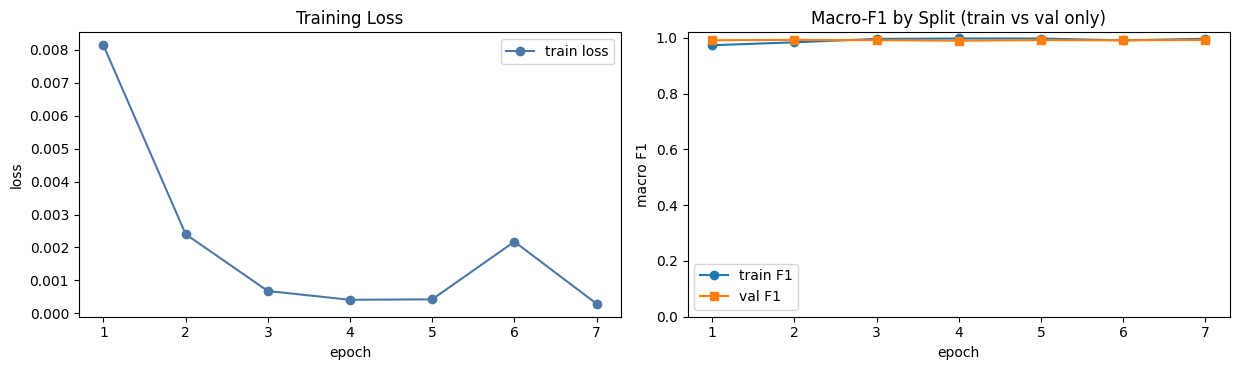

In [ ]:
history_df: Optional[pd.DataFrame] = None
train_val_current_ckpt: Optional[Path] = None
train_val_best_ckpt: Optional[Path] = None
head: Optional[nn.Module] = None

if RUN_TRAIN_VAL_TRAINING:
    if original_feature_frame is None or augmented_feature_frame is None:
        raise RuntimeError("Original and augmented feature frames required before training")
    if feature_extractor is None or encoder_info is None:
        raise RuntimeError("feature_extractor not built; ensure the encoder cell ran")

    device_head = DEVICE
    head = HierarchicalClassifierHead(2 * encoder_info.hidden_size).to(device_head)

    head, history_df, train_val_current_ckpt, train_val_best_ckpt = train_with_val_split(
        original_feature_frame,
        augmented_feature_frame,
        feature_extractor,
        head,
        encoder_info.hidden_size,
        encoder_info.num_register_tokens,
        device_head,
    )

    history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)
    print("Training complete.")
    print("Current (latest) checkpoint:", train_val_current_ckpt)
    print("Best (by val macro-F1) checkpoint:", train_val_best_ckpt)
    display(history_df)

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))

    ax = axes[0]
    ax.plot(history_df["epoch"], history_df["train_loss"], marker="o", color="#4c78a8", label="train loss")
    ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_title("Training Loss")
    ax.legend()

    ax2 = axes[1]
    ax2.plot(history_df["epoch"], history_df["train_macro_f1"], marker="o", label="train F1")
    ax2.plot(history_df["epoch"], history_df["val_macro_f1"], marker="s", label="val F1")
    ax2.set_xlabel("epoch"); ax2.set_ylabel("macro F1"); ax2.set_title("Macro-F1 by Split (train vs val only)")
    ax2.set_ylim(0, 1.02)
    ax2.legend()

    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "training_curve.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Training skipped. Set RUN_TRAIN_VAL_TRAINING=True.")

## 13. Inferensi Data Uji

Bagian ini menghasilkan berkas *submission* dari data uji tanpa label. Langkahnya:

1. Memuat *checkpoint* `train_val_best_val.pt`. Jika berkas tersebut tidak ditemukan, digunakan `train_val_current.pt`.
2. Memprediksi data uji dengan TTA tiga *view* (citra asli, *flip* horizontal, dan *zoom-in* 90%), lalu merata-ratakan probabilitasnya.
3. Membandingkan hasil TTA dengan prediksi tanpa TTA untuk melihat berapa prediksi yang berubah.
4. Menyimpan `submission_siglip2_trainval.csv` dan `test_probabilities.csv`.

Prediksi data uji tidak dinilai di dalam notebook ini.

In [ ]:
test_df: Optional[pd.DataFrame] = None
test_probabilities: Optional[np.ndarray] = None
test_predictions: Optional[np.ndarray] = None
SUBMISSION_PATH = OUTPUT_DIR / "submission_siglip2_trainval.csv"
TEST_PROB_PATH = OUTPUT_DIR / "test_probabilities.csv"

if RUN_TEST_INFERENCE:
    if feature_extractor is None or encoder_info is None:
        raise RuntimeError("Encoder must be loaded for test inference")

    test_df = load_test_metadata()
    print("Test images:", len(test_df))

    # Load the trained weights into the in-memory encoder + a fresh head.
    # The submission model is the BEST-BY-VAL checkpoint (highest validation
    # macro-F1) -- the only selection criterion in this notebook. Falls back to
    # current/latest if best_val wasn't saved for some reason.
    base_encoder = unwrap_encoder(feature_extractor)
    best_val_ckpt_file = OUTPUT_DIR / "train_val_best_val.pt"
    current_ckpt_file = OUTPUT_DIR / "train_val_current.pt"
    if best_val_ckpt_file.exists():
        ckpt_file = best_val_ckpt_file
        tag = "best-by-val-macro-F1"
    else:
        ckpt_file = current_ckpt_file
        tag = "current/latest (fallback: no best-by-val checkpoint found)"

    if ckpt_file.exists():
        ckpt = torch.load(ckpt_file, map_location="cpu")
        base_encoder.load_state_dict(ckpt["encoder_state_dict"])
        infer_head = HierarchicalClassifierHead(2 * encoder_info.hidden_size)
        infer_head.load_state_dict(ckpt["head_state_dict"])
        infer_head = infer_head.to(DEVICE)
        # Load the learnable attention-pooling weights too (replaces mean-pool).
        base_fe_for_load = unwrap_feature_extractor(feature_extractor)
        if "attn_pool_state_dict" in ckpt:
            base_fe_for_load.attn_pool.load_state_dict(ckpt["attn_pool_state_dict"])
        else:
            print("  WARNING: checkpoint has no attn_pool_state_dict -- using the "
                  "current in-memory AttentionPool weights.")
        print(f"Loaded {tag} checkpoint:", ckpt_file)
        print(f"  checkpoint epoch={ckpt.get('epoch')} "
              f"val_macro_f1={fmt_metric_id(ckpt.get('val_macro_f1'))} "
              f"train_macro_f1={fmt_metric_id(ckpt.get('train_macro_f1'))}")
    elif head is not None:
        infer_head = head
        print("Using in-memory trained head (no checkpoint on disk).")
    else:
        raise FileNotFoundError("No train/val checkpoint and no in-memory head available.")
    base_encoder.to(DEVICE).eval()

    test_frame = test_df.copy()
    test_frame["aug_idx"] = -1

    # TTA for the final test inference. per_view_probs[0] is the identity view
    # (pixel-identical to a plain non-TTA predict_probs pass), so the no-TTA-vs-TTA
    # comparison below is free -- no extra forward pass. No ground truth is used
    # anywhere in this cell.
    test_probabilities, _, _, _, test_per_view_probs = predict_probs_tta(
        feature_extractor, infer_head, test_frame, DEVICE, VISION_MEAN, VISION_STD, PADDING_VALUE,
        n_views=TTA_N_VIEWS,
    )
    test_predictions = test_probabilities.argmax(axis=1).astype(int)

    test_probabilities_no_tta = test_per_view_probs[0]
    test_predictions_no_tta = test_probabilities_no_tta.argmax(axis=1).astype(int)
    tta_agreement = float((test_predictions == test_predictions_no_tta).mean())
    n_changed = int((test_predictions != test_predictions_no_tta).sum())
    print(f"TTA{TTA_N_VIEWS}x vs no-TTA on test set: agreement={fmt_metric_id(tta_agreement)} "
          f"({n_changed}/{len(test_predictions)} predictions changed by TTA)")

    submission = pd.DataFrame({"id": test_df["id"].astype(int), "predicted": test_predictions})
    assert list(submission.columns) == ["id", "predicted"]
    assert set(submission["predicted"].unique()).issubset({0, 1, 2})
    submission.to_csv(SUBMISSION_PATH, index=False)
    pd.DataFrame({
        "id": submission["id"],
        "prob_0": test_probabilities[:, 0],
        "prob_1": test_probabilities[:, 1],
        "prob_2": test_probabilities[:, 2],
        "predicted": submission["predicted"],
    }).to_csv(TEST_PROB_PATH, index=False)
    print("Saved submission:", SUBMISSION_PATH, "| rows:", len(submission))
    display(submission.head())
else:
    print("Test inference skipped. Set RUN_TEST_INFERENCE=True.")


Test images: 1458


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Loaded best-by-val-macro-F1 checkpoint: /kaggle/working/outputs/siglip2_400_224/train_val_best_val.pt
  checkpoint epoch=2 val_macro_f1=99,2889198586 train_macro_f1=98,4190506785


/usr/lib/python3.12/multiprocessing/popen_fork.py:66: DeprecationWarning: This process (pid=58) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()


inference:   0%|          | 0/6 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at /pytorch/aten/src/ATen/native/Memory.cpp:46.)
  return data.pin_memory(device)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at /pytorch/aten/src/ATen/native/Memory.cpp:31.)
  return data.pin_memory(device)


inference:   0%|          | 0/6 [00:00<?, ?it/s]

inference:   0%|          | 0/6 [00:00<?, ?it/s]

TTA3x vs no-TTA on test set: agreement=99,6570644719 (5/1458 predictions changed by TTA)
Saved submission: /kaggle/working/outputs/siglip2_400_224/submission_siglip2_trainval.csv | rows: 1458


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,id,predicted
0,1,2
1,2,2
2,3,2
3,4,1
4,5,0


## 14. Ringkasan

Sel berikut mencetak konfigurasi akhir eksperimen, *epoch* terbaik menurut validasi, dan daftar berkas keluaran. Pemilihan model dan pelaporan hanya didasarkan pada pembagian data `train` dan `val`.

In [ ]:
best_epoch_row = None
if history_df is not None and len(history_df) > 0:
    best_epoch_row = history_df.loc[history_df["val_macro_f1"].idxmax()]

summary = {
    "SigLIP checkpoint": MODEL_NAME,
    "Image resolution": IMAGE_SIZE,
    "Training strategy": TRAINING_STRATEGY,
    "Val split ratio": VAL_SPLIT_RATIO,
    "Augmentation": AUGMENTATION_VERSION,
    "Augmented views per train image": AUGS_PER_IMAGE,
    "Encoder status": "Partial fine-tune",
    "Feature representation": "pooled vision output + attention-pooled patch tokens",
    "Head": (
        f"Hierarchical: Stage1 Electronic-vs-Rest + Stage2 Recyclable-vs-Organic, "
        f"each LayerNorm + MLP(hidden={HEAD_HIDDEN_DIM}, dropout={HEAD_DROPOUT})"
    ),
    "Loss": "focal" if USE_FOCAL_LOSS else "cross_entropy",
    "Multi-GPU": f"{'DataParallel x' + str(torch.cuda.device_count()) if USE_DATA_PARALLEL else 'single-device'}",
    "Checkpoint selection": "validation macro-F1 only (best epoch, not the last epoch)",
    "Submission checkpoint": "best-by-val, falls back to current/latest",
    "Best epoch (by val)": None if best_epoch_row is None else int(best_epoch_row["epoch"]),
    "Best epoch (by val) train F1": None if best_epoch_row is None else float(best_epoch_row["train_macro_f1"]),
    "Best epoch (by val) val F1": None if best_epoch_row is None else float(best_epoch_row["val_macro_f1"]),
    "Output directory": str(OUTPUT_DIR),
    "Submission path": str(SUBMISSION_PATH) if SUBMISSION_PATH.exists() else "not generated",
}

for key, value in summary.items():
    print(f"{key}: {value}")

print("\nExpected main artifacts after full run:")
for name in [
    "train_val_current.pt (latest epoch) / train_val_best_val.pt (best by val macro-F1)",
    "training_history.csv / training_curve.png (train F1 vs val F1)",
    "submission_siglip2_trainval.csv",
    "test_probabilities.csv",
]:
    print(" -", name)

SigLIP checkpoint: google/siglip2-so400m-patch14-224
Image resolution: 224
Training strategy: train_val_split_pure
Val split ratio: 0.1
Augmentation: pil_crop_flip_rotate_translate_color_blur_gray_cutout_v2
Augmented views per train image: 4
Encoder status: Partial fine-tune
Feature representation: pooled vision output + attention-pooled patch tokens
Head: Hierarchical: Stage1 Electronic-vs-Rest + Stage2 Recyclable-vs-Organic, each LayerNorm + MLP(hidden=512, dropout=0.3)
Loss: focal
Multi-GPU: DataParallel x2
Checkpoint selection: validation macro-F1 only (best epoch, not the last epoch)
Submission checkpoint: best-by-val, falls back to current/latest
Best epoch (by val): 2
Best epoch (by val) train F1: 0.9841905067850837
Best epoch (by val) val F1: 0.9928891985855164
Output directory: /kaggle/working/outputs/siglip2_400_224
Submission path: /kaggle/working/outputs/siglip2_400_224/submission_siglip2_trainval.csv

Expected main artifacts after full run:
 - train_val_current.pt (latest 

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 15. Penyimpanan *Checkpoint* ke Hugging Face

*Checkpoint* terbaik disimpan di Hugging Face agar dapat dipakai kembali tanpa melatih ulang. Langkahnya:

1. Mengambil `train_val_best_val.pt` dari `OUTPUT_DIR`.
2. Mengautentikasi ke Hugging Face menggunakan token dari Kaggle Secrets dengan nama `HF_TOKEN` (izin *write*). Token tidak ditulis di dalam notebook, dan opsi *Internet* pada Kaggle harus aktif.
3. Mengunggah berkas ke repositori dataset [ayaayaa/train-val-best-test](https://huggingface.co/datasets/ayaayaa/train-val-best-test) dengan nama berkas `train_val_best_test.pt`.

Hasil unggahan dapat diakses di [train_val_best_test.pt](https://huggingface.co/datasets/ayaayaa/train-val-best-test/blob/main/train_val_best_test.pt).

In [ ]:
from huggingface_hub import HfApi

HF_REPO_ID = "ayaayaa/train-val-best-test"
HF_REPO_TYPE = "dataset"
HF_FILE_IN_REPO = "train_val_best_test.pt"
LOCAL_BEST_CKPT = OUTPUT_DIR / "train_val_best_val.pt"

if not LOCAL_BEST_CKPT.exists():
    raise FileNotFoundError(f"Checkpoint terbaik tidak ditemukan: {LOCAL_BEST_CKPT}")

# Token dibaca dari Kaggle Secrets (nama: HF_TOKEN) atau dari variabel lingkungan HF_TOKEN.
try:
    from kaggle_secrets import UserSecretsClient
    hf_token = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    hf_token = os.environ.get("HF_TOKEN")

if not hf_token:
    raise RuntimeError(
        "HF_TOKEN tidak ditemukan. Tambahkan token (izin write) pada Kaggle Secrets, "
        "lalu jalankan ulang sel ini."
    )

api = HfApi(token=hf_token)
api.create_repo(repo_id=HF_REPO_ID, repo_type=HF_REPO_TYPE, exist_ok=True)

print(f"Mengunggah {LOCAL_BEST_CKPT.name} ({LOCAL_BEST_CKPT.stat().st_size / 1024**3:.2f} GB) ...")
api.upload_file(
    path_or_fileobj=str(LOCAL_BEST_CKPT),
    path_in_repo=HF_FILE_IN_REPO,
    repo_id=HF_REPO_ID,
    repo_type=HF_REPO_TYPE,
    commit_message="Unggah checkpoint terbaik (macro-F1 validasi tertinggi)",
)
print("Berhasil diunggah:", f"https://huggingface.co/datasets/{HF_REPO_ID}/blob/main/{HF_FILE_IN_REPO}")